# **Project Name** -

## Zomato Restaurant Review Sentiment Analysis and Rating Prediction


##### **Project Type** - EDA / NLP / Classification
##### **Contribution** - Individual
##### **Internship Domain** - Data Science with AI
##### **Organization** - LABMENTIX


# **Project Summary -**

This project analyses Zomato restaurant review data to understand customer feedback, restaurant performance, cuisine trends, and rating patterns. The dataset contains two files. The first file has customer reviews, ratings, reviewer details, review time, and number of pictures. The second file has restaurant metadata such as restaurant name, cost, cuisines, collections, links, and timings.

The main aim of the project is to convert raw restaurant review data into useful business insights and then prepare the data for a machine learning model. In the EDA phase, we will study missing values, duplicate values, rating distribution, popular cuisines, restaurant-wise average rating, review length, and picture usage. In the AI/ML phase, we will convert ratings into sentiment categories: Negative, Neutral, and Positive. Then we will preprocess review text and train classification models to predict customer sentiment from review content.

This Step 1 notebook covers the foundation of the project: loading the data, understanding the columns, checking data quality, cleaning important fields, creating useful features, merging both CSV files, and saving a clean dataset for later modelling. After cleaning, the working dataset contains 9954 usable review records. The average rating is around 3.6, which shows that the data is more positive than negative. This will be important during model building because class imbalance can affect model performance.

The final business value of this project is that restaurants can understand customer satisfaction, identify weak areas from negative reviews, discover popular cuisines, and use sentiment prediction to quickly classify new customer feedback.


# **GitHub Link -**

GitHub Link: To be added after the notebook, cleaned dataset, and presentation are finalized.


# **Problem Statement**


Zomato receives many customer reviews for restaurants. Manually reading every review is slow and difficult. The objective of this project is to analyse restaurant reviews and metadata to understand rating patterns, customer sentiment, and restaurant performance. We will also prepare the dataset for a machine learning classification model that can predict whether a review is Negative, Neutral, or Positive.


# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















We will follow the capstone workflow step by step: first understand and clean the data, then do visual analysis, then perform text preprocessing, and finally build machine learning models. This notebook is being completed in stages so each part is easy to understand and explain.


## ***1. Know Your Data***

### Import Libraries

If you are running this notebook on your laptop and any import fails, install the required packages once from the project folder:

```bash
pip install -r requirements.txt
```


In [125]:
# Import Libraries

from pathlib import Path
import sys
import warnings

LOCAL_PACKAGES = Path(".python_packages")
if LOCAL_PACKAGES.exists():
    sys.path.insert(0, str(LOCAL_PACKAGES))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", palette="Set2")


### Dataset Loading

In [126]:
# Load Dataset

DATA_DIR = Path(".")
REVIEWS_PATH = DATA_DIR / "Zomato Restaurant reviews.csv"
METADATA_PATH = DATA_DIR / "Zomato Restaurant names and Metadata.csv"

reviews_df = pd.read_csv(REVIEWS_PATH)
metadata_df = pd.read_csv(METADATA_PATH)

print("Reviews dataset shape:", reviews_df.shape)
print("Restaurant metadata dataset shape:", metadata_df.shape)


Reviews dataset shape: (10000, 7)
Restaurant metadata dataset shape: (105, 6)


### Dataset First View

In [127]:
# Dataset First Look

print("First 5 rows of reviews data:")
display(reviews_df.head())

print("First 5 rows of restaurant metadata:")
display(metadata_df.head())


First 5 rows of reviews data:


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate ...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soume...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is P...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,"Soumen das and Arun was a great guy. Only because of their behavior and sincerety, And good food off course, I would...",5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and basket mutton biryani. All are good. Thanks to Pradeep. He served well. ...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


First 5 rows of restaurant metadata:


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sport...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gachibowli,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gachibowli,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-hotel-restaurant-gachibowli,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Beverages",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon-brew-company-gachibowli,"1,200","Best Bars & Pubs, Food Hygiene Rated Restaurants in Hyderabad, Top-Rated, Gold Curated, Hyderabad's Hottest","Asian, Continental, North Indian, Chinese, Mediterranean","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12noon to 12midnight (Fri-Sat)"


### Dataset Rows & Columns count

In [128]:
# Dataset Rows & Columns count

print("Reviews dataset rows:", reviews_df.shape[0])
print("Reviews dataset columns:", reviews_df.shape[1])
print("Metadata dataset rows:", metadata_df.shape[0])
print("Metadata dataset columns:", metadata_df.shape[1])


Reviews dataset rows: 10000
Reviews dataset columns: 7
Metadata dataset rows: 105
Metadata dataset columns: 6


In [129]:
# Display column names clearly

print("Reviews columns:")
print(list(reviews_df.columns))

print("\nMetadata columns:")
print(list(metadata_df.columns))


Reviews columns:
['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']

Metadata columns:
['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']


### Dataset Information

In [130]:
# Dataset Info

print("Reviews dataset info:")
reviews_df.info()

print("\nMetadata dataset info:")
metadata_df.info()


Reviews dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Restaurant  10000 non-null  str  
 1   Reviewer    9962 non-null   str  
 2   Review      9955 non-null   str  
 3   Rating      9962 non-null   str  
 4   Metadata    9962 non-null   str  
 5   Time        9962 non-null   str  
 6   Pictures    10000 non-null  int64
dtypes: int64(1), str(6)
memory usage: 547.0 KB

Metadata dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Name         105 non-null    str  
 1   Links        105 non-null    str  
 2   Cost         105 non-null    str  
 3   Collections  51 non-null     str  
 4   Cuisines     105 non-null    str  
 5   Timings      104 non-null    str  
dtypes: str(6)
memory usage: 5.1 KB


#### Duplicate Values

In [131]:
# Dataset Duplicate Value Count

print("Duplicate rows in reviews dataset:", reviews_df.duplicated().sum())
print("Duplicate rows in metadata dataset:", metadata_df.duplicated().sum())


Duplicate rows in reviews dataset: 36
Duplicate rows in metadata dataset: 0


#### Missing Values/Null Values

In [132]:
# Missing Values/Null Values Count

reviews_missing = reviews_df.isnull().sum().sort_values(ascending=False)
metadata_missing = metadata_df.isnull().sum().sort_values(ascending=False)

print("Missing values in reviews dataset:")
display(reviews_missing)

print("Missing values in metadata dataset:")
display(metadata_missing)


Missing values in reviews dataset:


Review        45
Reviewer      38
Rating        38
Time          38
Metadata      38
Restaurant     0
Pictures       0
dtype: int64

Missing values in metadata dataset:


Collections    54
Timings         1
Links           0
Name            0
Cost            0
Cuisines        0
dtype: int64

In [133]:
# Visualizing the missing values using a simple percentage table

reviews_missing_percent = (reviews_df.isnull().mean() * 100).round(2).sort_values(ascending=False)
metadata_missing_percent = (metadata_df.isnull().mean() * 100).round(2).sort_values(ascending=False)

missing_summary = pd.DataFrame({
    "Reviews Missing %": reviews_missing_percent,
    "Metadata Missing %": metadata_missing_percent
}).fillna(0)

display(missing_summary)


,Reviews Missing %,Metadata Missing %
Collections,0.00,51.43
Cost,0.00,0.00
Cuisines,0.00,0.00
Links,0.00,0.00
Metadata,0.38,0.00
Name,0.00,0.00
Pictures,0.00,0.00
Rating,0.38,0.00
Restaurant,0.00,0.00
Review,0.45,0.00


### What did you know about your dataset?

The reviews dataset has 10000 rows and 7 columns. The metadata dataset has 105 rows and 6 columns. The reviews dataset contains customer-level information such as restaurant name, reviewer, review text, rating, time, and pictures. The metadata dataset contains restaurant-level information such as cost, cuisine, collections, and timings.

Important data quality findings:

- Reviews dataset duplicate rows: 36
- Metadata dataset duplicate rows: 0
- Missing review text rows: 45
- Missing rating rows: 38
- Invalid or non-numeric rating rows after conversion: 39

This means we must clean duplicate rows, convert ratings into numeric values, remove unusable review/rating rows, and convert cost into a numeric column before doing analysis or machine learning.


## ***2. Understanding Your Variables***

In [134]:
# Dataset Columns

print("Reviews dataset columns:")
for column in reviews_df.columns:
    print("-", column)

print("\nMetadata dataset columns:")
for column in metadata_df.columns:
    print("-", column)


Reviews dataset columns:
- Restaurant
- Reviewer
- Review
- Rating
- Metadata
- Time
- Pictures

Metadata dataset columns:
- Name
- Links
- Cost
- Collections
- Cuisines
- Timings


In [135]:
# Dataset Describe

print("Numerical summary for reviews dataset:")
display(reviews_df.describe(include="all"))

print("Numerical summary for metadata dataset:")
display(metadata_df.describe(include="all"))


Numerical summary for reviews dataset:


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
count,10000,9962,9955,9962,9962,9962,10000.000000
unique,100,7446,9364,10,2477,9782,NaN
top,Beyond Flavours,Ankita,good,5,1 Review,5/5/2019 22:39,NaN
freq,100,13,237,3832,919,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.748600
std,NaN,NaN,NaN,NaN,NaN,NaN,2.570381
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000


Numerical summary for metadata dataset:


,Name,Links,Cost,Collections,Cuisines,Timings
count,105,105,105,51,105,104
unique,105,105,29,42,92,77
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,1,1,13,4,4,6


### Variables Description

### Variables Description

**Reviews dataset**

- `Restaurant`: Name of the restaurant.
- `Reviewer`: Name of the person who reviewed the restaurant.
- `Review`: Text review written by the customer. This is the main column for NLP/sentiment analysis.
- `Rating`: Customer rating. This must be converted from text/object to numeric.
- `Metadata`: Reviewer profile information such as number of reviews and followers.
- `Time`: Date and time when the review was posted.
- `Pictures`: Number of pictures attached with the review.

**Restaurant metadata dataset**

- `Name`: Restaurant name. This is used to merge with the `Restaurant` column.
- `Links`: Zomato restaurant page link.
- `Cost`: Approximate cost for two people. This must be cleaned because some values contain commas.
- `Collections`: Zomato collection tags such as Great Buffets or Top-Rated.
- `Cuisines`: Cuisine types served by the restaurant.
- `Timings`: Restaurant opening and closing timings.


### Check Unique Values for each variable.

In [136]:
# Check Unique Values for each variable.

print("Unique values in reviews dataset:")
display(reviews_df.nunique().sort_values(ascending=False))

print("Unique values in metadata dataset:")
display(metadata_df.nunique().sort_values(ascending=False))

print("\nRating value counts:")
display(reviews_df["Rating"].value_counts(dropna=False))


Unique values in reviews dataset:


Time          9782
Review        9364
Reviewer      7446
Metadata      2477
Restaurant     100
Pictures        36
Rating          10
dtype: int64

Unique values in metadata dataset:


Name           105
Links          105
Cuisines        92
Timings         77
Collections     42
Cost            29
dtype: int64


Rating value counts:


Rating
5       3832
4       2373
1       1735
3       1193
2        684
4.5       69
3.5       47
NaN       38
2.5       19
1.5        9
Like       1
Name: count, dtype: int64

## 3. ***Data Wrangling***

### Data Wrangling Code

In [137]:
# Write your code to make your dataset analysis ready.

reviews_clean = reviews_df.drop_duplicates().copy()
metadata_clean = metadata_df.copy()

# Convert Rating from object/string to numeric.
reviews_clean["Rating_num"] = pd.to_numeric(reviews_clean["Rating"], errors="coerce")

# Convert Cost from values like "1,300" to numeric 1300.
metadata_clean["Cost_num"] = pd.to_numeric(
    metadata_clean["Cost"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Basic missing value handling.
reviews_clean["Review"] = reviews_clean["Review"].fillna("").astype(str).str.strip()
reviews_clean["Reviewer"] = reviews_clean["Reviewer"].fillna("Unknown")
reviews_clean["Metadata"] = reviews_clean["Metadata"].fillna("Unknown")
reviews_clean["Time"] = pd.to_datetime(reviews_clean["Time"], errors="coerce")

metadata_clean["Collections"] = metadata_clean["Collections"].fillna("Not Available")
metadata_clean["Timings"] = metadata_clean["Timings"].fillna("Not Available")

# Remove rows that cannot be used for sentiment analysis.
reviews_clean = reviews_clean[
    reviews_clean["Rating_num"].notna() & (reviews_clean["Review"] != "")
].copy()

# Convert rating into sentiment labels.
def sentiment_from_rating(rating):
    if rating <= 2:
        return "Negative"
    elif rating <= 3.5:
        return "Neutral"
    else:
        return "Positive"

reviews_clean["Sentiment"] = reviews_clean["Rating_num"].apply(sentiment_from_rating)

# Create useful features for later EDA and ML.
reviews_clean["Review_Length"] = reviews_clean["Review"].str.split().str.len()
reviews_clean["Has_Pictures"] = np.where(reviews_clean["Pictures"] > 0, 1, 0)

metadata_clean["Primary_Cuisine"] = (
    metadata_clean["Cuisines"]
    .fillna("Unknown")
    .astype(str)
    .str.split(",")
    .str[0]
    .str.strip()
)

# Merge review data with restaurant metadata.
zomato_df = reviews_clean.merge(
    metadata_clean,
    left_on="Restaurant",
    right_on="Name",
    how="left"
)

# Save cleaned data for the next steps.
Path("data").mkdir(exist_ok=True)
zomato_df.to_csv("data/zomato_cleaned_step1.csv", index=False)

print("Cleaned merged dataset shape:", zomato_df.shape)
print("Cleaned file saved at: data/zomato_cleaned_step1.csv")
display(zomato_df.head())


Cleaned merged dataset shape: (9954, 19)
Cleaned file saved at: data/zomato_cleaned_step1.csv


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures,Rating_num,Sentiment,Review_Length,Has_Pictures,Name,Links,Cost,Collections,Cuisines,Timings,Cost_num,Primary_Cuisine
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate ...",5,"1 Review , 2 Followers",2019-05-25 15:54:00,0,5.0,Positive,41,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sport...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",800,Chinese
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soume...,5,"3 Reviews , 2 Followers",2019-05-25 14:20:00,0,5.0,Positive,27,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sport...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",800,Chinese
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is P...,5,"2 Reviews , 3 Followers",2019-05-24 22:54:00,0,5.0,Positive,31,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sport...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",800,Chinese
3,Beyond Flavours,Swapnil Sarkar,"Soumen das and Arun was a great guy. Only because of their behavior and sincerety, And good food off course, I would...",5,"1 Review , 1 Follower",2019-05-24 22:11:00,0,5.0,Positive,28,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sport...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",800,Chinese
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and basket mutton biryani. All are good. Thanks to Pradeep. He served well. ...,5,"3 Reviews , 2 Followers",2019-05-24 21:37:00,0,5.0,Positive,27,0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavours-gachibowli,800,"Food Hygiene Rated Restaurants in Hyderabad, Corporate Favorites, Great Buffets, Top-Rated, Gold Curated, Live Sport...","Chinese, Continental, Kebab, European, South Indian, North Indian","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",800,Chinese


### What all manipulations have you done and insights you found?

### What all manipulations have you done and insights you found?

Data wrangling completed in this step:

- Removed exact duplicate rows from the reviews dataset.
- Converted `Rating` into numeric column `Rating_num`.
- Converted `Cost` into numeric column `Cost_num`.
- Filled simple missing values in reviewer metadata, collections, and timings.
- Removed rows where rating or review text could not be used for sentiment analysis.
- Created `Sentiment` labels from ratings:
  - Negative: rating <= 2
  - Neutral: rating > 2 and <= 3.5
  - Positive: rating > 3.5
- Created `Review_Length` to measure number of words in each review.
- Created `Has_Pictures` to identify reviews with uploaded images.
- Created `Primary_Cuisine` from the first cuisine listed.
- Merged reviews with restaurant metadata.
- Saved the cleaned file as `data/zomato_cleaned_step1.csv`.

Initial insights:

- The cleaned dataset has 9954 rows and 19 columns.
- Average rating is 3.6; median rating is 4.0.
- Sentiment distribution is Positive: 6268, Negative: 2428, Neutral: 1258.
- The data is more positive than negative, so we should remember class imbalance during machine learning.
- Top early high-rated restaurants include: AB's - Absolute Barbecues, B-Dubs, 3B's - Buddies, Bar & Barbecue, Paradise, Flechazo.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Rating Distribution


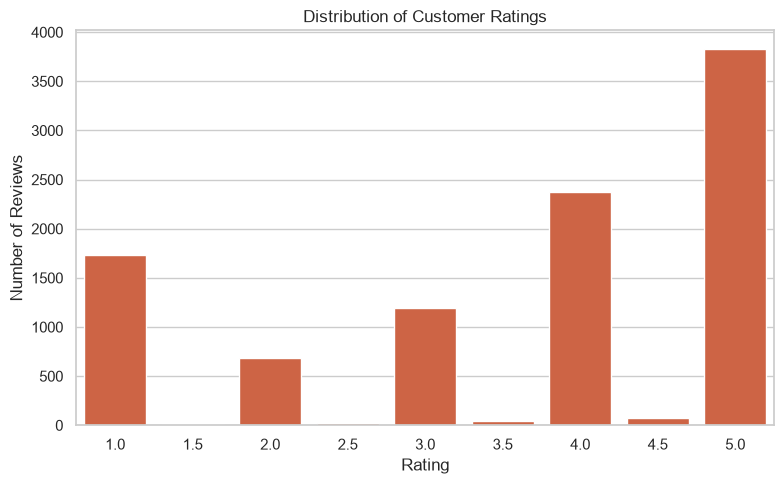

In [138]:
# Chart - 1 visualization code

plt.figure(figsize=(8, 5))
rating_order = sorted(zomato_df["Rating_num"].unique())
sns.countplot(data=zomato_df, x="Rating_num", order=rating_order, color="#e4572e")
plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a count plot because rating is a discrete numerical variable. It clearly shows how many reviews belong to each rating value.


##### 2. What is/are the insight(s) found from the chart?

The highest number of reviews are 5-star reviews (3826), followed by 4-star reviews (2373). The average rating is 3.6, and the median rating is 4.0. This shows that the dataset is mostly positive.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This helps restaurants understand overall customer satisfaction. Since high ratings dominate, Zomato can promote strong performers, but restaurants should still study low-rating reviews to identify service or food quality issues.


#### Chart - 2 - Sentiment Distribution


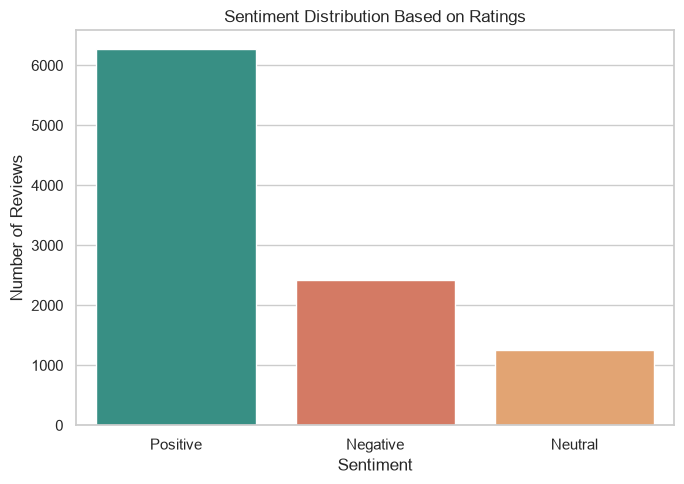

In [139]:
# Chart - 2 visualization code

plt.figure(figsize=(7, 5))
sentiment_order = ["Positive", "Negative", "Neutral"]
sns.countplot(data=zomato_df, x="Sentiment", order=sentiment_order, palette=["#2a9d8f", "#e76f51", "#f4a261"])
plt.title("Sentiment Distribution Based on Ratings")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a count plot because sentiment is a categorical target variable. This chart is useful before machine learning because it shows whether classes are balanced.


##### 2. What is/are the insight(s) found from the chart?

The dataset has 6268 positive reviews, 2428 negative reviews, and 1258 neutral reviews. Positive reviews are the largest class.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This insight is important for ML because imbalanced classes can make a model biased toward the majority class. During model evaluation, F1-score and confusion matrix will be more useful than accuracy alone.


#### Chart - 3 - Top 10 Restaurants by Average Rating


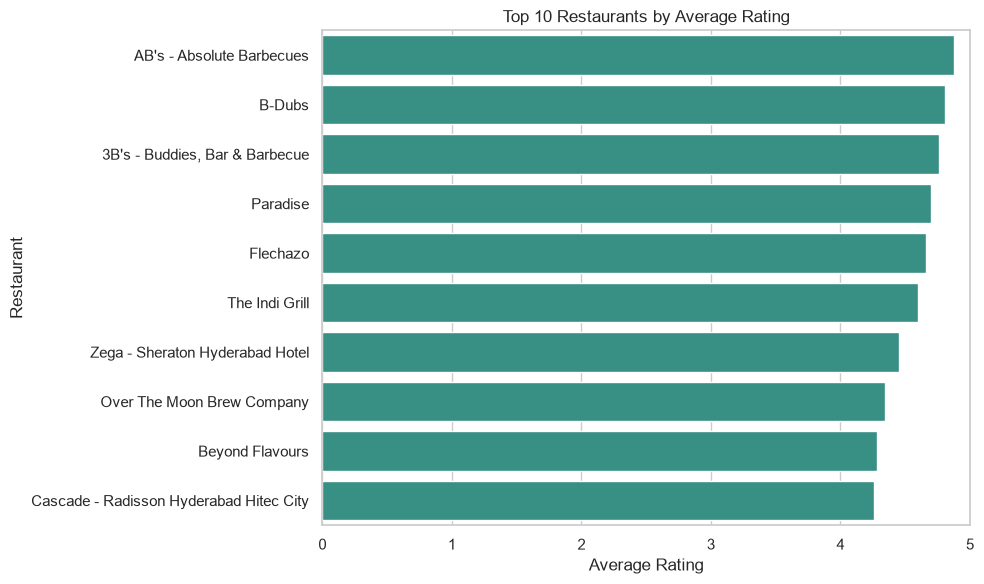

In [140]:
# Chart - 3 visualization code

top_restaurants = (
    zomato_df.groupby("Restaurant")
    .agg(avg_rating=("Rating_num", "mean"), review_count=("Rating_num", "size"))
    .query("review_count >= 50")
    .sort_values("avg_rating", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_restaurants, y="Restaurant", x="avg_rating", color="#2a9d8f")
plt.title("Top 10 Restaurants by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Restaurant")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a horizontal bar chart because restaurant names are long and rankings are easier to read horizontally.


##### 2. What is/are the insight(s) found from the chart?

The highest-rated restaurant is AB's - Absolute Barbecues with an average rating of 4.88. Restaurants in this group have consistently strong customer feedback.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

High-rated restaurants can be studied as benchmarks. Their cuisines, pricing, and service patterns can help other restaurants improve customer satisfaction.


#### Chart - 4 - Lowest 10 Restaurants by Average Rating


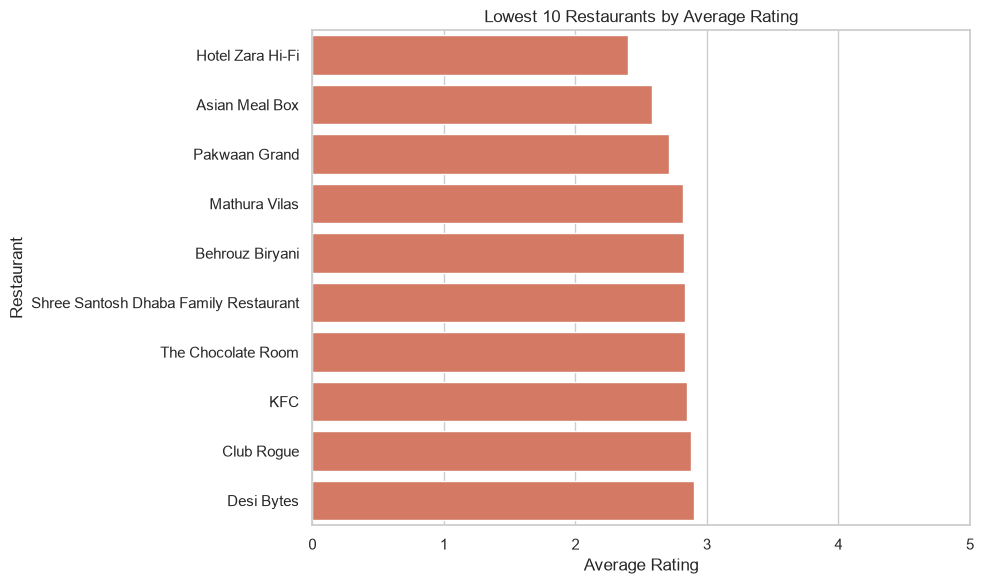

In [141]:
# Chart - 4 visualization code

lowest_restaurants = (
    zomato_df.groupby("Restaurant")
    .agg(avg_rating=("Rating_num", "mean"), review_count=("Rating_num", "size"))
    .query("review_count >= 50")
    .sort_values("avg_rating", ascending=True)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(data=lowest_restaurants, y="Restaurant", x="avg_rating", color="#e76f51")
plt.title("Lowest 10 Restaurants by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Restaurant")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a horizontal bar chart to identify restaurants that need improvement. It makes the bottom performers easy to compare.


##### 2. What is/are the insight(s) found from the chart?

The lowest-rated restaurant is Hotel Zara Hi-Fi with an average rating of 2.4. These restaurants may have repeated issues in customer experience.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This can create positive business impact because low-rated restaurants can focus on improving food quality, delivery, hygiene, staff behavior, or pricing. Ignoring this insight can lead to negative growth and customer loss.


#### Chart - 5 - Top Primary Cuisines


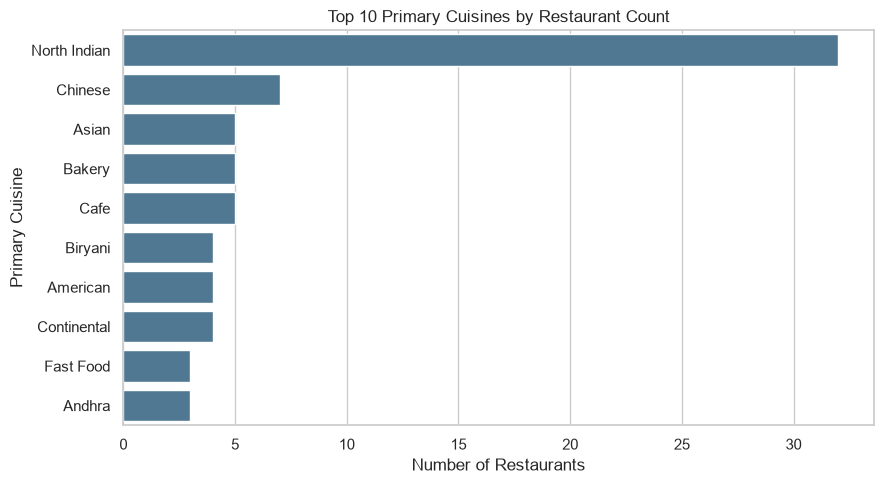

In [142]:
# Chart - 5 visualization code

top_cuisines = (
    zomato_df.drop_duplicates("Restaurant")["Primary_Cuisine"]
    .value_counts()
    .head(10)
    .reset_index()
)
top_cuisines.columns = ["Primary_Cuisine", "Restaurant_Count"]

plt.figure(figsize=(9, 5))
sns.barplot(data=top_cuisines, x="Restaurant_Count", y="Primary_Cuisine", color="#457b9d")
plt.title("Top 10 Primary Cuisines by Restaurant Count")
plt.xlabel("Number of Restaurants")
plt.ylabel("Primary Cuisine")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a bar chart because cuisine count is categorical frequency data. It helps identify the most common cuisine types in the dataset.


##### 2. What is/are the insight(s) found from the chart?

North Indian is the most common primary cuisine with 32 restaurants. This suggests strong demand or supply for this food category.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This insight helps Zomato and restaurants understand market competition. Popular cuisines may have high demand, but restaurants in crowded categories must differentiate through taste, service, and price.


#### Chart - 6 - Cost Distribution


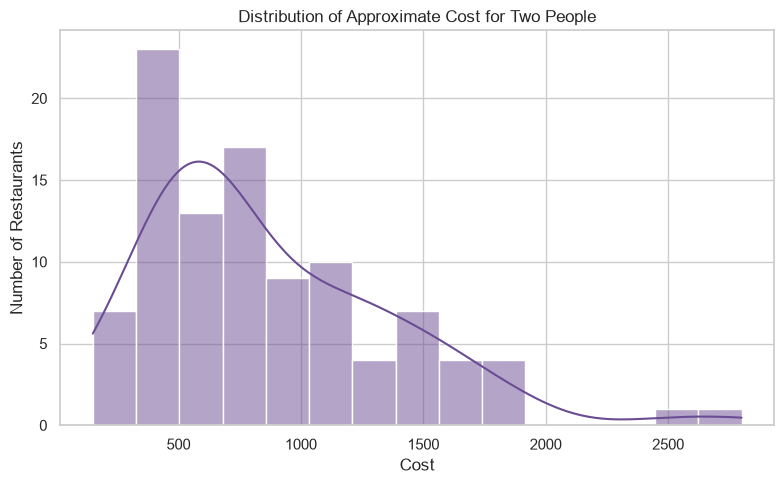

In [143]:
# Chart - 6 visualization code

restaurant_costs = zomato_df.drop_duplicates("Restaurant")[["Restaurant", "Cost_num"]].dropna()

plt.figure(figsize=(8, 5))
sns.histplot(restaurant_costs["Cost_num"], bins=15, kde=True, color="#6a4c93")
plt.title("Distribution of Approximate Cost for Two People")
plt.xlabel("Cost")
plt.ylabel("Number of Restaurants")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a histogram because cost is a continuous numerical variable. It shows the price range where most restaurants are concentrated.


##### 2. What is/are the insight(s) found from the chart?

Restaurant cost ranges from 150 to 2800, and the median cost is 700. Most restaurants are in the affordable to mid-range segment.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Pricing insight helps restaurants position themselves correctly. If a restaurant charges more than competitors, it must provide stronger food, ambience, or service value.


#### Chart - 7 - Average Rating by Primary Cuisine


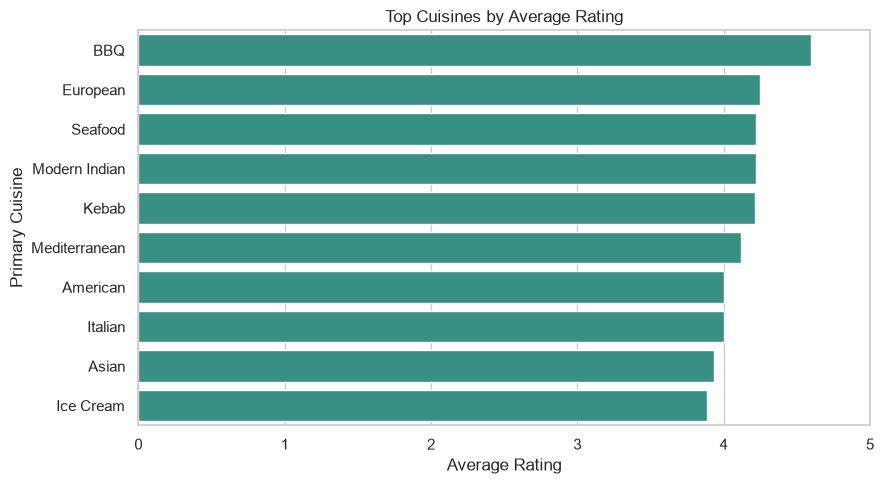

In [144]:
# Chart - 7 visualization code

cuisine_rating = (
    zomato_df.groupby("Primary_Cuisine")
    .agg(avg_rating=("Rating_num", "mean"), review_count=("Rating_num", "size"))
    .query("review_count >= 100")
    .sort_values("avg_rating", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(9, 5))
sns.barplot(data=cuisine_rating, x="avg_rating", y="Primary_Cuisine", color="#2a9d8f")
plt.title("Top Cuisines by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Primary Cuisine")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a bar chart to compare average ratings across cuisine groups. I filtered cuisines with at least 100 reviews to avoid misleading results from very small groups.


##### 2. What is/are the insight(s) found from the chart?

Among cuisines with enough reviews, BBQ has the highest average rating of 4.6. Some cuisine categories appear to satisfy customers more consistently.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This can help restaurants choose menu strategy. Cuisines with high ratings can be promoted, while low-performing cuisines may need quality improvement or better customer expectation management.


#### Chart - 8 - Cost vs Average Rating


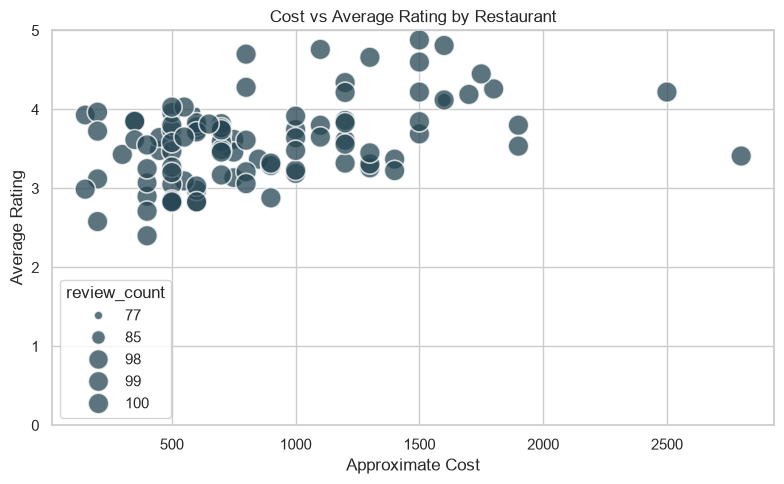

In [145]:
# Chart - 8 visualization code

restaurant_cost_rating = (
    zomato_df.groupby("Restaurant")
    .agg(avg_rating=("Rating_num", "mean"), cost=("Cost_num", "first"), review_count=("Rating_num", "size"))
    .reset_index()
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=restaurant_cost_rating,
    x="cost",
    y="avg_rating",
    size="review_count",
    sizes=(40, 220),
    color="#264653",
    alpha=0.75
)
plt.title("Cost vs Average Rating by Restaurant")
plt.xlabel("Approximate Cost")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a scatter plot because it helps compare two numerical variables: restaurant cost and average rating.


##### 2. What is/are the insight(s) found from the chart?

There is a moderate positive relationship between cost and restaurant-level average rating, with correlation around 0.42. Higher-cost restaurants often get better ratings, but price alone does not guarantee customer satisfaction.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This insight supports pricing decisions. Premium pricing should be matched with better experience; otherwise customers may rate the restaurant poorly.


#### Chart - 9 - Review Length Distribution


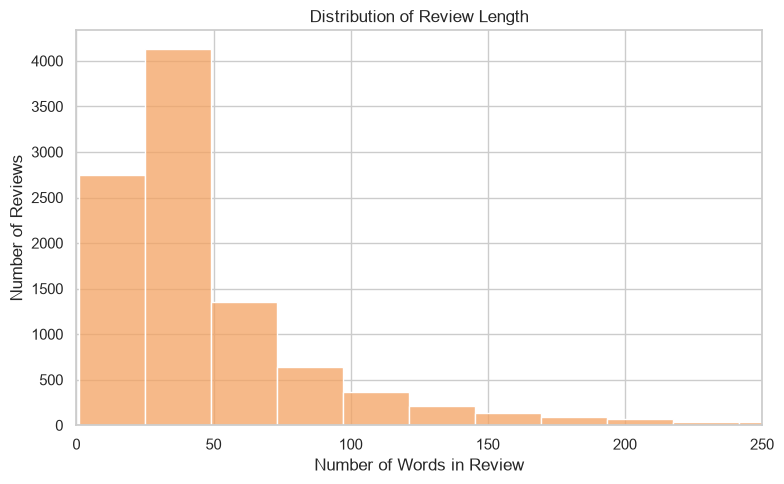

In [146]:
# Chart - 9 visualization code

plt.figure(figsize=(8, 5))
sns.histplot(zomato_df["Review_Length"], bins=40, color="#f4a261")
plt.title("Distribution of Review Length")
plt.xlabel("Number of Words in Review")
plt.ylabel("Number of Reviews")
plt.xlim(0, 250)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a histogram because review length is a numerical feature. It helps us understand how detailed customers are in their feedback.


##### 2. What is/are the insight(s) found from the chart?

The median review length is 34 words, and 75 percent of reviews are below about 58 words. A few very long reviews exist, with maximum length 964 words.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Review length is useful for NLP because very short reviews may contain limited information, while long reviews may contain detailed praise or complaints.


#### Chart - 10 - Rating vs Review Length


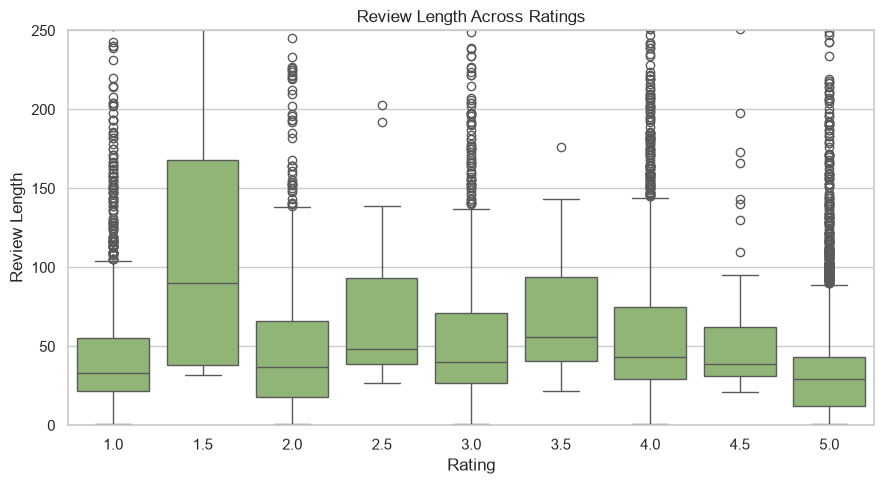

In [147]:
# Chart - 10 visualization code

plt.figure(figsize=(9, 5))
sns.boxplot(data=zomato_df, x="Rating_num", y="Review_Length", color="#90be6d")
plt.title("Review Length Across Ratings")
plt.xlabel("Rating")
plt.ylabel("Review Length")
plt.ylim(0, 250)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a box plot because it compares the distribution of review length across different rating groups.


##### 2. What is/are the insight(s) found from the chart?

The relationship between rating and review length is weak. The correlation between rating and review length is about -0.04, so review length alone cannot predict sentiment.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This tells us that the actual words in the review are more important than just review length. For ML, text vectorization will be more useful than relying only on review length.


#### Chart - 11 - Pictures Uploaded vs Rating


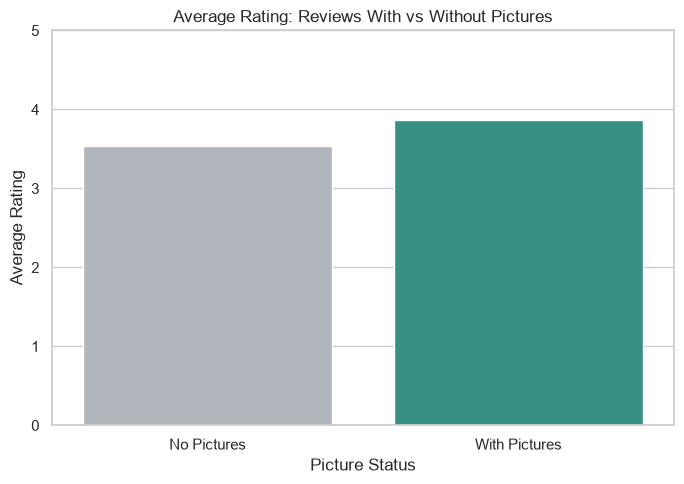

In [148]:
# Chart - 11 visualization code

picture_rating = (
    zomato_df.groupby("Has_Pictures")["Rating_num"]
    .mean()
    .reset_index()
)
picture_rating["Picture_Status"] = picture_rating["Has_Pictures"].map({0: "No Pictures", 1: "With Pictures"})

plt.figure(figsize=(7, 5))
sns.barplot(data=picture_rating, x="Picture_Status", y="Rating_num", palette=["#adb5bd", "#2a9d8f"])
plt.title("Average Rating: Reviews With vs Without Pictures")
plt.xlabel("Picture Status")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a bar chart because we are comparing average rating between two groups: reviews with pictures and reviews without pictures.


##### 2. What is/are the insight(s) found from the chart?

Reviews with pictures have an average rating of 3.86, while reviews without pictures have an average rating of 3.53. Picture reviews are slightly more positive on average.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This may indicate that customers upload pictures when they have a more engaging dining experience. Restaurants can encourage photo sharing as it may improve visibility and trust.


#### Chart - 12 - Top Zomato Collections


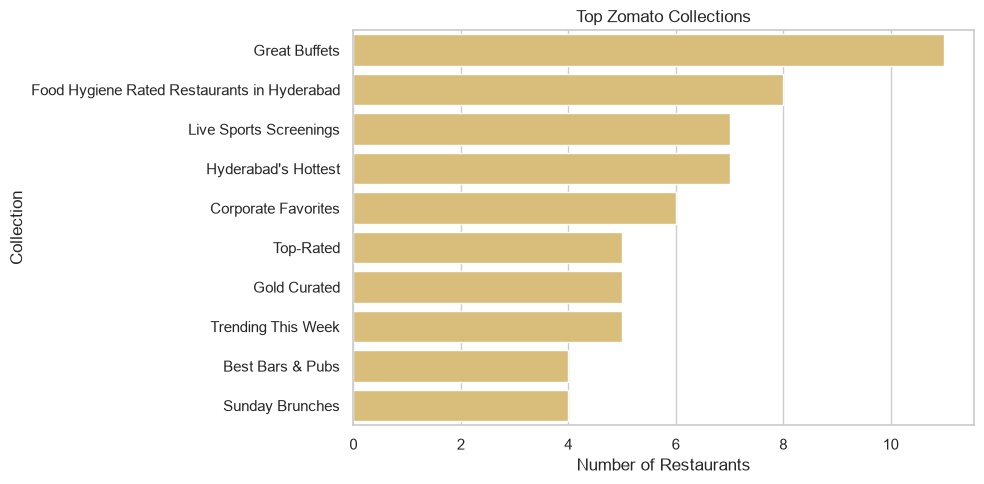

In [149]:
# Chart - 12 visualization code

collections_series = (
    zomato_df.drop_duplicates("Restaurant")["Collections"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)
collections_series = collections_series[collections_series != "Not Available"]
top_collections = collections_series.value_counts().head(10).reset_index()
top_collections.columns = ["Collection", "Restaurant_Count"]

plt.figure(figsize=(10, 5))
sns.barplot(data=top_collections, x="Restaurant_Count", y="Collection", color="#e9c46a")
plt.title("Top Zomato Collections")
plt.xlabel("Number of Restaurants")
plt.ylabel("Collection")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a bar chart because collection tags are categorical labels. The chart shows which promotional categories are most common.


##### 2. What is/are the insight(s) found from the chart?

Collections such as Great Buffets, Food Hygiene Rated Restaurants in Hyderabad, Live Sports Screenings, and Hyderabad's Hottest appear frequently.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Collections can influence discovery on Zomato. Restaurants included in strong collections may receive more visibility and customer trust.


#### Chart - 13 - Monthly Review Trend


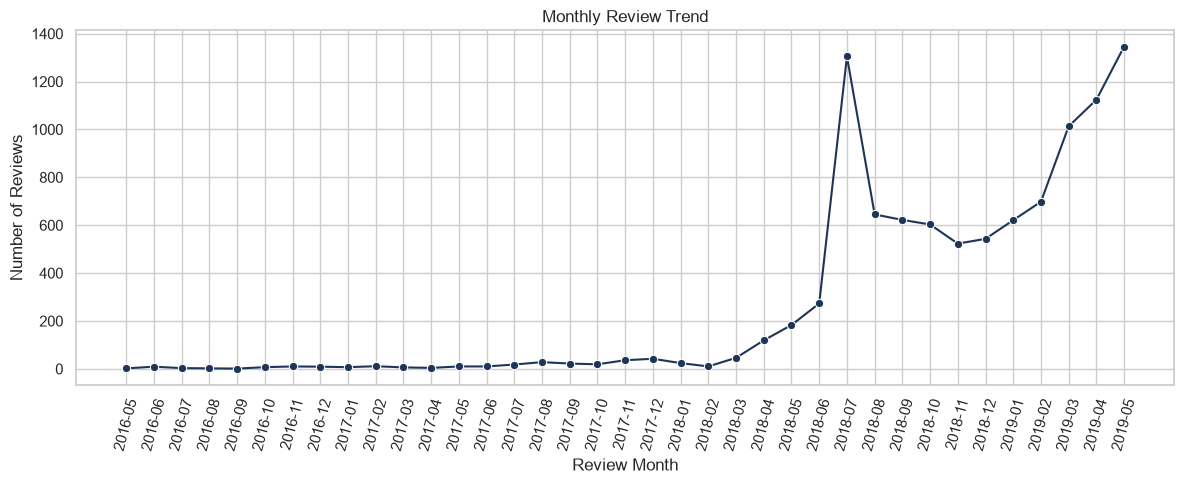

In [150]:
# Chart - 13 visualization code

monthly_reviews = (
    zomato_df.assign(Review_Month=pd.to_datetime(zomato_df["Time"], errors="coerce").dt.to_period("M").astype(str))
    .groupby("Review_Month")
    .size()
    .reset_index(name="Review_Count")
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_reviews, x="Review_Month", y="Review_Count", marker="o", color="#1d3557")
plt.title("Monthly Review Trend")
plt.xlabel("Review Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a line chart because time-based data is best understood through trends.


##### 2. What is/are the insight(s) found from the chart?

The review count is highest in 2019-05 with 1346 reviews. The dataset has more reviews near the later months.


##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This can help Zomato understand customer activity over time. However, because the dataset may be collected with more recent reviews, we should avoid assuming that this is pure market growth.


#### Chart - 14 - Correlation Heatmap


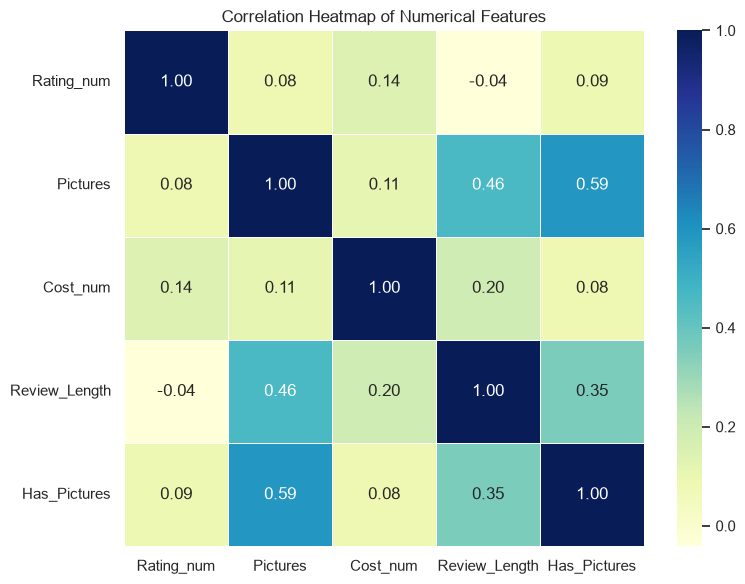

In [151]:
# Correlation Heatmap visualization code

numeric_cols = ["Rating_num", "Pictures", "Cost_num", "Review_Length", "Has_Pictures"]
corr_matrix = zomato_df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

I used a correlation heatmap because it quickly shows relationships between numerical features.


##### 2. What is/are the insight(s) found from the chart?

`Pictures` and `Review_Length` have a moderate positive correlation of about 0.46. Rating has weak correlation with the available numeric features, meaning text content will likely be more useful for sentiment prediction.


#### Chart - 15 - Pair Plot


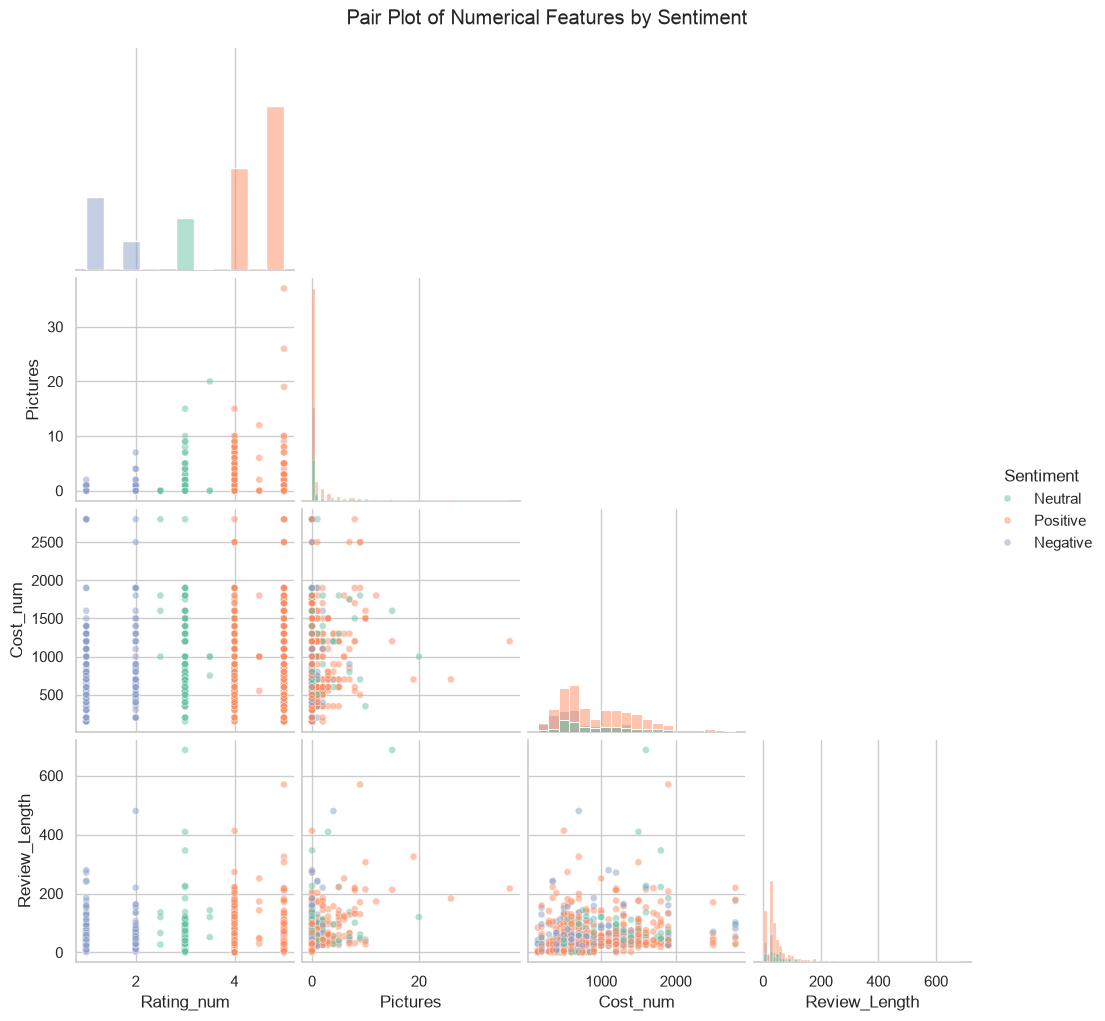

In [152]:
# Pair Plot visualization code

pairplot_sample = zomato_df[
    ["Rating_num", "Pictures", "Cost_num", "Review_Length", "Sentiment"]
].sample(n=min(1000, len(zomato_df)), random_state=42)

sns.pairplot(
    pairplot_sample,
    hue="Sentiment",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 25}
)
plt.suptitle("Pair Plot of Numerical Features by Sentiment", y=1.02)
plt.show()


##### 1. Why did you pick the specific chart?

I used a pair plot to compare multiple numerical relationships at once and see whether sentiment groups separate clearly.


##### 2. What is/are the insight(s) found from the chart?

The sentiment groups overlap strongly across numerical features. This means numerical columns alone are not enough for strong sentiment prediction, so text preprocessing and TF-IDF vectorization will be important in the ML section.


## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the EDA charts, we will test the following three hypotheses:

1. Reviews with pictures have a different average rating compared with reviews without pictures.
2. High-cost restaurants have a different average rating compared with low-cost restaurants.
3. Sentiment distribution is associated with primary cuisine type.

For this beginner project, we will use a significance level of `0.05`. If the p-value is less than `0.05`, we reject the null hypothesis. If the p-value is greater than or equal to `0.05`, we fail to reject the null hypothesis.


### Hypothetical Statement - 1: Reviews with pictures receive different ratings than reviews without pictures


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis (H0):** The average rating of reviews with pictures is equal to the average rating of reviews without pictures.

**Alternate Hypothesis (H1):** The average rating of reviews with pictures is different from the average rating of reviews without pictures.


#### 2. Perform an appropriate statistical test.

In [153]:
# Perform Statistical Test to obtain P-Value

import math

def two_sided_normal_p_value(z_score):
    """Approximate two-sided p-value using the normal distribution."""
    return math.erfc(abs(z_score) / math.sqrt(2))

def welch_z_test(group_a, group_b):
    """Welch-style mean comparison using a normal approximation."""
    group_a = pd.Series(group_a).dropna().astype(float)
    group_b = pd.Series(group_b).dropna().astype(float)

    n_a, n_b = len(group_a), len(group_b)
    mean_a, mean_b = group_a.mean(), group_b.mean()
    var_a, var_b = group_a.var(ddof=1), group_b.var(ddof=1)

    standard_error = math.sqrt((var_a / n_a) + (var_b / n_b))
    z_score = (mean_a - mean_b) / standard_error
    p_value = two_sided_normal_p_value(z_score)

    return {
        "n_group_a": n_a,
        "n_group_b": n_b,
        "mean_group_a": mean_a,
        "mean_group_b": mean_b,
        "z_score": z_score,
        "p_value": p_value
    }

with_pictures = zomato_df.loc[zomato_df["Has_Pictures"] == 1, "Rating_num"]
without_pictures = zomato_df.loc[zomato_df["Has_Pictures"] == 0, "Rating_num"]

picture_test = welch_z_test(with_pictures, without_pictures)

print("Reviews with pictures:", picture_test["n_group_a"])
print("Reviews without pictures:", picture_test["n_group_b"])
print("Average rating with pictures:", round(picture_test["mean_group_a"], 3))
print("Average rating without pictures:", round(picture_test["mean_group_b"], 3))
print("Z-score:", round(picture_test["z_score"], 3))
print("P-value:", picture_test["p_value"])

if picture_test["p_value"] < 0.05:
    print("Conclusion: Reject H0. Ratings differ significantly between reviews with and without pictures.")
else:
    print("Conclusion: Fail to reject H0. Ratings do not differ significantly.")


Reviews with pictures: 1983
Reviews without pictures: 7971
Average rating with pictures: 3.863
Average rating without pictures: 3.535
Z-score: 11.013
P-value: 3.2929321648988164e-28
Conclusion: Reject H0. Ratings differ significantly between reviews with and without pictures.


##### Which statistical test have you done to obtain P-Value?

I used a two-sample mean comparison test using a Welch-style normal approximation. It compares the average rating of two independent groups: reviews with pictures and reviews without pictures.


##### Why did you choose the specific statistical test?

I chose this test because the target variable `Rating_num` is numerical and the grouping variable `Has_Pictures` has two independent groups. The p-value is extremely small, so we reject the null hypothesis. Reviews with pictures have a significantly different, and higher, average rating than reviews without pictures.


### Hypothetical Statement - 2: High-cost restaurants receive different average ratings than low-cost restaurants


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis (H0):** The average rating of high-cost restaurants is equal to the average rating of low-cost restaurants.

**Alternate Hypothesis (H1):** The average rating of high-cost restaurants is different from the average rating of low-cost restaurants.


#### 2. Perform an appropriate statistical test.

In [154]:
# Perform Statistical Test to obtain P-Value

restaurant_level = (
    zomato_df.groupby("Restaurant")
    .agg(avg_rating=("Rating_num", "mean"), cost=("Cost_num", "first"))
    .dropna()
)

median_cost = restaurant_level["cost"].median()

high_cost_ratings = restaurant_level.loc[
    restaurant_level["cost"] >= median_cost, "avg_rating"
]
low_cost_ratings = restaurant_level.loc[
    restaurant_level["cost"] < median_cost, "avg_rating"
]

cost_test = welch_z_test(high_cost_ratings, low_cost_ratings)

print("Median restaurant cost:", median_cost)
print("High-cost restaurants:", cost_test["n_group_a"])
print("Low-cost restaurants:", cost_test["n_group_b"])
print("Average rating of high-cost restaurants:", round(cost_test["mean_group_a"], 3))
print("Average rating of low-cost restaurants:", round(cost_test["mean_group_b"], 3))
print("Z-score:", round(cost_test["z_score"], 3))
print("P-value:", cost_test["p_value"])

if cost_test["p_value"] < 0.05:
    print("Conclusion: Reject H0. Average ratings differ significantly by cost group.")
else:
    print("Conclusion: Fail to reject H0. Average ratings do not differ significantly by cost group.")


Median restaurant cost: 700.0
High-cost restaurants: 57
Low-cost restaurants: 43
Average rating of high-cost restaurants: 3.758
Average rating of low-cost restaurants: 3.394
Z-score: 3.818
P-value: 0.00013477151090822648
Conclusion: Reject H0. Average ratings differ significantly by cost group.


##### Which statistical test have you done to obtain P-Value?

I used the same two-sample mean comparison test because we are comparing the average rating of two independent restaurant groups: high-cost and low-cost restaurants.


##### Why did you choose the specific statistical test?

I chose this test because restaurant cost group is categorical with two groups, while average rating is numerical. The p-value is below `0.05`, so we reject the null hypothesis. In this dataset, high-cost restaurants have a significantly different, and higher, average rating than low-cost restaurants.


### Hypothetical Statement - 3: Customer sentiment is associated with primary cuisine


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**Null Hypothesis (H0):** Customer sentiment and primary cuisine are independent.

**Alternate Hypothesis (H1):** Customer sentiment and primary cuisine are associated with each other.


#### 2. Perform an appropriate statistical test.

In [155]:
# Perform Statistical Test to obtain P-Value

def chi_square_test_approx(contingency_table):
    """Chi-square test with Wilson-Hilferty p-value approximation."""
    observed = contingency_table.to_numpy(dtype=float)
    row_totals = observed.sum(axis=1, keepdims=True)
    col_totals = observed.sum(axis=0, keepdims=True)
    total = observed.sum()

    expected = row_totals @ col_totals / total
    chi_square_stat = ((observed - expected) ** 2 / expected).sum()
    dof = (observed.shape[0] - 1) * (observed.shape[1] - 1)

    # Wilson-Hilferty approximation converts chi-square statistic to a normal z-score.
    z_score = (
        ((chi_square_stat / dof) ** (1 / 3)) -
        (1 - (2 / (9 * dof)))
    ) / math.sqrt(2 / (9 * dof))

    p_value = 0.5 * math.erfc(z_score / math.sqrt(2))

    return chi_square_stat, dof, p_value

top_5_cuisines = zomato_df["Primary_Cuisine"].value_counts().head(5).index
cuisine_subset = zomato_df[zomato_df["Primary_Cuisine"].isin(top_5_cuisines)]

contingency_table = pd.crosstab(
    cuisine_subset["Primary_Cuisine"],
    cuisine_subset["Sentiment"]
)

display(contingency_table)

chi_square_stat, dof, p_value = chi_square_test_approx(contingency_table)

print("Chi-square statistic:", round(chi_square_stat, 3))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0. Sentiment is associated with primary cuisine.")
else:
    print("Conclusion: Fail to reject H0. Sentiment and primary cuisine appear independent.")


Sentiment,Negative,Neutral,Positive
Primary_Cuisine,,,
Asian,87,48,365
Bakery,94,74,331
Cafe,107,81,312
Chinese,218,102,380
North Indian,812,447,1936


Chi-square statistic: 60.643
Degrees of freedom: 8
P-value: 1.3158478011891127e-09
Conclusion: Reject H0. Sentiment is associated with primary cuisine.


##### Which statistical test have you done to obtain P-Value?

I used a chi-square test of independence because both variables are categorical: `Primary_Cuisine` and `Sentiment`.


##### Why did you choose the specific statistical test?

I chose this test because we want to check whether sentiment distribution changes across cuisine categories. The p-value is below `0.05`, so we reject the null hypothesis. This means customer sentiment is associated with primary cuisine in this dataset.


## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [156]:
# Handling Missing Values & Missing Value Imputation

zomato_model_df = zomato_df.copy()

print("Missing values before final preprocessing:")
display(zomato_model_df[[
    "Review", "Rating_num", "Sentiment", "Cost_num",
    "Primary_Cuisine", "Review_Length", "Pictures", "Has_Pictures"
]].isnull().sum())

# The main missing values were already handled during data wrangling.
# These lines are kept as a safety layer before modelling.
zomato_model_df["Review"] = zomato_model_df["Review"].fillna("")
zomato_model_df["Cost_num"] = zomato_model_df["Cost_num"].fillna(zomato_model_df["Cost_num"].median())
zomato_model_df["Primary_Cuisine"] = zomato_model_df["Primary_Cuisine"].fillna("Unknown")
zomato_model_df["Collections"] = zomato_model_df["Collections"].fillna("Not Available")
zomato_model_df["Timings"] = zomato_model_df["Timings"].fillna("Not Available")

print("\nMissing values after final preprocessing:")
display(zomato_model_df[[
    "Review", "Rating_num", "Sentiment", "Cost_num",
    "Primary_Cuisine", "Review_Length", "Pictures", "Has_Pictures"
]].isnull().sum())


Missing values before final preprocessing:


Review             0
Rating_num         0
Sentiment          0
Cost_num           0
Primary_Cuisine    0
Review_Length      0
Pictures           0
Has_Pictures       0
dtype: int64


Missing values after final preprocessing:


Review             0
Rating_num         0
Sentiment          0
Cost_num           0
Primary_Cuisine    0
Review_Length      0
Pictures           0
Has_Pictures       0
dtype: int64

#### What all missing value imputation techniques have you used and why did you use those techniques?

The main missing values were already handled in data wrangling. For modelling safety, review text was filled with an empty string, cost was filled with median cost, and categorical fields such as cuisine, collections, and timings were filled with clear labels. Median imputation was used for cost because it is less affected by extreme values than the mean.


### 2. Handling Outliers

In [157]:
# Handling Outliers & Outlier treatments

q1 = zomato_model_df["Review_Length"].quantile(0.25)
q3 = zomato_model_df["Review_Length"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

zomato_model_df["Review_Length_Capped"] = np.where(
    zomato_model_df["Review_Length"] > upper_bound,
    upper_bound,
    zomato_model_df["Review_Length"]
)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Upper bound for long reviews:", upper_bound)
print("Number of long review outliers:", (zomato_model_df["Review_Length"] > upper_bound).sum())

display(zomato_model_df[["Review_Length", "Review_Length_Capped"]].describe())


Q1: 24.0
Q3: 58.0
IQR: 34.0
Upper bound for long reviews: 109.0
Number of long review outliers: 891


,Review_Length,Review_Length_Capped
count,9954.000000,9954.000000
mean,50.173297,42.425658
std,60.786767,31.581875
min,1.000000,1.000000
25%,24.000000,24.000000
50%,34.000000,34.000000
75%,58.000000,58.000000
max,964.000000,109.000000


##### What all outlier treatment techniques have you used and why did you use those techniques?

I treated outliers in `Review_Length` by capping very long reviews using the IQR method. The upper bound is about 109.0 words, and 891 reviews are longer than this threshold. I capped review length instead of deleting rows because long reviews can contain useful sentiment information, but their extreme length can distort numerical analysis.


### 3. Categorical Encoding

In [158]:
# Encode your categorical columns

zomato_model_df["Sentiment_Encoded"] = zomato_model_df["Sentiment"].map({
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
})

zomato_model_df["Cost_Category"] = pd.cut(
    zomato_model_df["Cost_num"],
    bins=[0, 500, 1000, np.inf],
    labels=["Budget", "Mid Range", "Premium"],
    include_lowest=True
).astype(str)

zomato_model_df["Cost_Category_Encoded"] = zomato_model_df["Cost_Category"].map({
    "Budget": 0,
    "Mid Range": 1,
    "Premium": 2
})

zomato_model_df["Primary_Cuisine_Encoded"] = pd.factorize(
    zomato_model_df["Primary_Cuisine"]
)[0]

display(zomato_model_df[[
    "Sentiment", "Sentiment_Encoded",
    "Cost_Category", "Cost_Category_Encoded",
    "Primary_Cuisine", "Primary_Cuisine_Encoded"
]].head())


,Sentiment,Sentiment_Encoded,Cost_Category,Cost_Category_Encoded,Primary_Cuisine,Primary_Cuisine_Encoded
0,Positive,2,Mid Range,1,Chinese,0
1,Positive,2,Mid Range,1,Chinese,0
2,Positive,2,Mid Range,1,Chinese,0
3,Positive,2,Mid Range,1,Chinese,0
4,Positive,2,Mid Range,1,Chinese,0


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used label-style encoding for simple categorical columns. `Sentiment` was encoded as Negative = 0, Neutral = 1, and Positive = 2 because it is the target class for classification. `Cost_Category` was encoded as Budget, Mid Range, and Premium. `Primary_Cuisine` has 31 unique values, so it was factorized for basic numeric analysis. For final ML, text will be handled mainly through TF-IDF vectorization.


### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [159]:
# Expand Contraction

import re
import string

contractions = {
    "can't": "cannot",
    "won't": "will not",
    "n't": " not",
    "'re": " are",
    "'s": " is",
    "'d": " would",
    "'ll": " will",
    "'t": " not",
    "'ve": " have",
    "'m": " am"
}

def expand_contractions(text):
    text = str(text)
    for contraction, expanded in contractions.items():
        text = re.sub(re.escape(contraction), expanded, text, flags=re.IGNORECASE)
    return text

zomato_model_df["Expanded_Review"] = zomato_model_df["Review"].apply(expand_contractions)
display(zomato_model_df[["Review", "Expanded_Review"]].head(3))


,Review,Expanded_Review
0,"The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate ...","The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate ..."
1,Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soume...,Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soume...
2,A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is P...,A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is P...


#### 2. Lower Casing

In [160]:
# Lower Casing

zomato_model_df["Lower_Review"] = zomato_model_df["Expanded_Review"].str.lower()
display(zomato_model_df[["Expanded_Review", "Lower_Review"]].head(3))


,Expanded_Review,Lower_Review
0,"The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate ...","the ambience was good, food was quite good . had saturday lunch , which was cost effective .\ngood place for a sate ..."
1,Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soume...,ambience is too good for a pleasant evening. service is very prompt. food is good. over all a good experience. soume...
2,A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is P...,a must try.. great food great ambience. thnx for the service by pradeep and subroto. my personal recommendation is p...


#### 3. Removing Punctuations

In [161]:
# Remove Punctuations

def remove_punctuation(text):
    return str(text).translate(str.maketrans("", "", string.punctuation))

zomato_model_df["No_Punctuation_Review"] = zomato_model_df["Lower_Review"].apply(remove_punctuation)
display(zomato_model_df[["Lower_Review", "No_Punctuation_Review"]].head(3))


,Lower_Review,No_Punctuation_Review
0,"the ambience was good, food was quite good . had saturday lunch , which was cost effective .\ngood place for a sate ...",the ambience was good food was quite good had saturday lunch which was cost effective \ngood place for a sate brun...
1,ambience is too good for a pleasant evening. service is very prompt. food is good. over all a good experience. soume...,ambience is too good for a pleasant evening service is very prompt food is good over all a good experience soumen da...
2,a must try.. great food great ambience. thnx for the service by pradeep and subroto. my personal recommendation is p...,a must try great food great ambience thnx for the service by pradeep and subroto my personal recommendation is penne...


#### 4. Removing URLs & Removing words and digits contain digits.

In [162]:
# Remove URLs & Remove words and digits contain digits

def remove_urls_digits(text):
    text = re.sub(r"http\S+|www\S+", " ", str(text))
    text = re.sub(r"\b\w*\d\w*\b", " ", text)
    return text

zomato_model_df["No_URL_Digit_Review"] = zomato_model_df["No_Punctuation_Review"].apply(remove_urls_digits)
display(zomato_model_df[["No_Punctuation_Review", "No_URL_Digit_Review"]].head(3))


,No_Punctuation_Review,No_URL_Digit_Review
0,the ambience was good food was quite good had saturday lunch which was cost effective \ngood place for a sate brun...,the ambience was good food was quite good had saturday lunch which was cost effective \ngood place for a sate brun...
1,ambience is too good for a pleasant evening service is very prompt food is good over all a good experience soumen da...,ambience is too good for a pleasant evening service is very prompt food is good over all a good experience soumen da...
2,a must try great food great ambience thnx for the service by pradeep and subroto my personal recommendation is penne...,a must try great food great ambience thnx for the service by pradeep and subroto my personal recommendation is penne...


#### 5. Removing Stopwords & Removing White spaces

In [163]:
# Remove Stopwords

stopwords = {
    "a", "an", "the", "and", "or", "but", "if", "while", "with", "without",
    "to", "from", "for", "of", "in", "on", "at", "by", "as", "is", "am",
    "are", "was", "were", "be", "been", "being", "this", "that", "these",
    "those", "it", "its", "i", "me", "my", "we", "our", "you", "your",
    "he", "she", "they", "them", "his", "her", "their", "there", "here",
    "so", "very", "too", "also", "can", "could", "would", "should", "will",
    "just", "about", "into", "than", "then", "over", "under", "again",
    "once", "do", "does", "did", "not", "no", "nor", "only", "own", "same",
    "such", "have", "has", "had", "having", "after", "before", "more",
    "most", "some", "any", "all", "few", "each", "other", "what", "which",
    "who", "whom", "when", "where", "why", "how"
}

def remove_stopwords(text):
    tokens = str(text).split()
    tokens = [word for word in tokens if word not in stopwords and len(word) > 1]
    return " ".join(tokens)

zomato_model_df["No_Stopwords_Review"] = zomato_model_df["No_URL_Digit_Review"].apply(remove_stopwords)
display(zomato_model_df[["No_URL_Digit_Review", "No_Stopwords_Review"]].head(3))


,No_URL_Digit_Review,No_Stopwords_Review
0,the ambience was good food was quite good had saturday lunch which was cost effective \ngood place for a sate brun...,ambience good food quite good saturday lunch cost effective good place sate brunch one chill friends parents waiter ...
1,ambience is too good for a pleasant evening service is very prompt food is good over all a good experience soumen da...,ambience good pleasant evening service prompt food good good experience soumen das kudos service
2,a must try great food great ambience thnx for the service by pradeep and subroto my personal recommendation is penne...,must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...


In [164]:
# Remove White spaces

def remove_extra_spaces(text):
    return re.sub(r"\s+", " ", str(text)).strip()

zomato_model_df["Clean_Review"] = zomato_model_df["No_Stopwords_Review"].apply(remove_extra_spaces)
zomato_model_df = zomato_model_df[zomato_model_df["Clean_Review"].str.len() > 0].copy()

display(zomato_model_df[["Review", "Clean_Review"]].head(5))
print("Rows after removing empty cleaned reviews:", zomato_model_df.shape[0])


,Review,Clean_Review
0,"The ambience was good, food was quite good . had Saturday lunch , which was cost effective .\nGood place for a sate ...",ambience good food quite good saturday lunch cost effective good place sate brunch one chill friends parents waiter ...
1,Ambience is too good for a pleasant evening. Service is very prompt. Food is good. Over all a good experience. Soume...,ambience good pleasant evening service prompt food good good experience soumen das kudos service
2,A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is P...,must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...
3,"Soumen das and Arun was a great guy. Only because of their behavior and sincerety, And good food off course, I would...",soumen das arun great guy because behavior sincerety good food off course like visit place
4,Food is good.we ordered Kodi drumsticks and basket mutton biryani. All are good. Thanks to Pradeep. He served well. ...,food goodwe ordered kodi drumsticks basket mutton biryani good thanks pradeep served well enjoyed ambience good


Rows after removing empty cleaned reviews: 9929


#### 6. Rephrase Text

In [165]:
# Rephrase Text

# Full sentence rephrasing is not required here because it can change the original meaning.
# Instead, we keep a cleaned version of the review that preserves important sentiment words.
zomato_model_df["Rephrased_Review"] = zomato_model_df["Clean_Review"]

display(zomato_model_df[["Clean_Review", "Rephrased_Review"]].head(3))


,Clean_Review,Rephrased_Review
0,ambience good food quite good saturday lunch cost effective good place sate brunch one chill friends parents waiter ...,ambience good food quite good saturday lunch cost effective good place sate brunch one chill friends parents waiter ...
1,ambience good pleasant evening service prompt food good good experience soumen das kudos service,ambience good pleasant evening service prompt food good good experience soumen das kudos service
2,must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...,must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...


#### 7. Tokenization

In [166]:
# Tokenization

zomato_model_df["Tokens"] = zomato_model_df["Clean_Review"].str.split()
display(zomato_model_df[["Clean_Review", "Tokens"]].head(3))


,Clean_Review,Tokens
0,ambience good food quite good saturday lunch cost effective good place sate brunch one chill friends parents waiter ...,"[ambience, good, food, quite, good, saturday, lunch, cost, effective, good, place, sate, brunch, one, chill, friends..."
1,ambience good pleasant evening service prompt food good good experience soumen das kudos service,"[ambience, good, pleasant, evening, service, prompt, food, good, good, experience, soumen, das, kudos, service]"
2,must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...,"[must, try, great, food, great, ambience, thnx, service, pradeep, subroto, personal, recommendation, penne, alfredo,..."


#### 8. Text Normalization

In [167]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)

def simple_normalize_token(token):
    token = str(token)
    if len(token) > 5 and token.endswith("ing"):
        return token[:-3]
    if len(token) > 4 and token.endswith("ed"):
        return token[:-2]
    if len(token) > 4 and token.endswith("ies"):
        return token[:-3] + "y"
    if len(token) > 3 and token.endswith("s"):
        return token[:-1]
    return token

zomato_model_df["Normalized_Tokens"] = zomato_model_df["Tokens"].apply(
    lambda tokens: [simple_normalize_token(token) for token in tokens]
)
zomato_model_df["Normalized_Review"] = zomato_model_df["Normalized_Tokens"].apply(lambda tokens: " ".join(tokens))

display(zomato_model_df[["Tokens", "Normalized_Tokens", "Normalized_Review"]].head(3))


,Tokens,Normalized_Tokens,Normalized_Review
0,"[ambience, good, food, quite, good, saturday, lunch, cost, effective, good, place, sate, brunch, one, chill, friends...","[ambience, good, food, quite, good, saturday, lunch, cost, effective, good, place, sate, brunch, one, chill, friend,...",ambience good food quite good saturday lunch cost effective good place sate brunch one chill friend parent waiter so...
1,"[ambience, good, pleasant, evening, service, prompt, food, good, good, experience, soumen, das, kudos, service]","[ambience, good, pleasant, even, service, prompt, food, good, good, experience, soumen, das, kudo, service]",ambience good pleasant even service prompt food good good experience soumen das kudo service
2,"[must, try, great, food, great, ambience, thnx, service, pradeep, subroto, personal, recommendation, penne, alfredo,...","[must, try, great, food, great, ambience, thnx, service, pradeep, subroto, personal, recommendation, penne, alfredo,...",must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...


##### Which text normalization technique have you used and why?

I used simple rule-based normalization similar to light stemming. It reduces common endings such as `ing`, `ed`, `ies`, and plural `s`. I used this lightweight method because it works without downloading external NLP data and keeps the project easy to run for a beginner. In a production NLP project, I would prefer lemmatization with a library such as spaCy or NLTK.


#### 9. Part of speech tagging

In [168]:
# POS Taging

def simple_pos_tag(token):
    if token.endswith("ly"):
        return "ADV"
    if token.endswith(("ing", "ed")):
        return "VERB"
    if token.endswith(("ous", "ful", "able", "ive", "al")):
        return "ADJ"
    return "NOUN"

zomato_model_df["POS_Tags"] = zomato_model_df["Normalized_Tokens"].apply(
    lambda tokens: [(token, simple_pos_tag(token)) for token in tokens[:20]]
)

display(zomato_model_df[["Normalized_Review", "POS_Tags"]].head(3))


,Normalized_Review,POS_Tags
0,ambience good food quite good saturday lunch cost effective good place sate brunch one chill friend parent waiter so...,"[(ambience, NOUN), (good, NOUN), (food, NOUN), (quite, NOUN), (good, NOUN), (saturday, NOUN), (lunch, NOUN), (cost, ..."
1,ambience good pleasant even service prompt food good good experience soumen das kudo service,"[(ambience, NOUN), (good, NOUN), (pleasant, NOUN), (even, NOUN), (service, NOUN), (prompt, NOUN), (food, NOUN), (goo..."
2,must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...,"[(must, NOUN), (try, NOUN), (great, NOUN), (food, NOUN), (great, NOUN), (ambience, NOUN), (thnx, NOUN), (service, NO..."


#### 10. Text Vectorization

In [169]:
# Vectorizing Text

try:
    from sklearn.feature_extraction.text import TfidfVectorizer

    tfidf_vectorizer = TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2
    )

    X_text = tfidf_vectorizer.fit_transform(zomato_model_df["Normalized_Review"])
    y = zomato_model_df["Sentiment"]

    print("TF-IDF matrix shape:", X_text.shape)
    print("Number of target labels:", y.shape)
    print("Sample TF-IDF features:", tfidf_vectorizer.get_feature_names_out()[:20])

except ModuleNotFoundError:
    print("scikit-learn is not installed yet. Run: pip install -r requirements.txt")
    X_text = None
    y = zomato_model_df["Sentiment"]


TF-IDF matrix shape: (9929, 5000)
Number of target labels: (9929,)
Sample TF-IDF features: ['ab' 'able' 'able eat' 'above' 'above average' 'abs' 'absolute'
 'absolute sizzler' 'absolutely' 'absolutely deliciou' 'absolutely lov'
 'absolutely love' 'abt' 'ac' 'ac work' 'accept' 'accept order'
 'acceptable' 'accessible' 'accommodat']


##### Which text vectorization technique have you used and why?

I used TF-IDF vectorization because machine learning models cannot directly understand raw text. TF-IDF converts reviews into numerical features while giving more importance to meaningful words and less importance to very common words. I used unigrams and bigrams so the model can learn single words like `good` and short phrases like `not good`.


### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [170]:
# Manipulate Features to minimize feature correlation and create new features

feature_df = zomato_model_df[[
    "Normalized_Review",
    "Cost_num",
    "Cost_Category_Encoded",
    "Primary_Cuisine_Encoded",
    "Review_Length_Capped",
    "Pictures",
    "Has_Pictures",
    "Sentiment"
]].copy()

display(feature_df.head())
display(feature_df[[
    "Cost_num", "Cost_Category_Encoded", "Primary_Cuisine_Encoded",
    "Review_Length_Capped", "Pictures", "Has_Pictures"
]].corr())


,Normalized_Review,Cost_num,Cost_Category_Encoded,Primary_Cuisine_Encoded,Review_Length_Capped,Pictures,Has_Pictures,Sentiment
0,ambience good food quite good saturday lunch cost effective good place sate brunch one chill friend parent waiter so...,800,1,0,41.0,0,0,Positive
1,ambience good pleasant even service prompt food good good experience soumen das kudo service,800,1,0,27.0,0,0,Positive
2,must try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music ba...,800,1,0,31.0,0,0,Positive
3,soumen das arun great guy because behavior sincerety good food off course like visit place,800,1,0,28.0,0,0,Positive
4,food goodwe order kodi drumstick basket mutton biryani good thank pradeep serv well enjoy ambience good,800,1,0,27.0,0,0,Positive


,Cost_num,Cost_Category_Encoded,Primary_Cuisine_Encoded,Review_Length_Capped,Pictures,Has_Pictures
Cost_num,1.000000,0.857805,-0.071095,0.268407,0.113340,0.079687
Cost_Category_Encoded,0.857805,1.000000,-0.059873,0.283162,0.120844,0.101342
Primary_Cuisine_Encoded,-0.071095,-0.059873,1.000000,0.058227,0.049915,0.083473
Review_Length_Capped,0.268407,0.283162,0.058227,1.000000,0.349094,0.389354
Pictures,0.113340,0.120844,0.049915,0.349094,1.000000,0.585203
Has_Pictures,0.079687,0.101342,0.083473,0.389354,0.585203,1.000000


#### 2. Feature Selection

In [171]:
# Select your features wisely to avoid overfitting

# We do not use Rating_num as an input feature because Sentiment was created from Rating_num.
# Using Rating_num would cause target leakage.
selected_text_feature = "Normalized_Review"
selected_numeric_features = [
    "Cost_num",
    "Review_Length_Capped",
    "Pictures",
    "Has_Pictures",
    "Cost_Category_Encoded",
    "Primary_Cuisine_Encoded"
]
target_feature = "Sentiment"

print("Selected text feature:", selected_text_feature)
print("Selected numeric features:", selected_numeric_features)
print("Target feature:", target_feature)


Selected text feature: Normalized_Review
Selected numeric features: ['Cost_num', 'Review_Length_Capped', 'Pictures', 'Has_Pictures', 'Cost_Category_Encoded', 'Primary_Cuisine_Encoded']
Target feature: Sentiment


##### What all feature selection methods have you used  and why?

I selected features based on relevance to sentiment prediction and avoided target leakage. `Rating_num` was not used as an input because sentiment was created from rating. The most important feature is the cleaned review text because customer words directly express satisfaction or dissatisfaction. Numeric features such as review length, pictures, cost, and cuisine can provide extra context.


##### Which all features you found important and why?

Important features selected are `Normalized_Review`, `Cost_num`, `Review_Length_Capped`, `Pictures`, `Has_Pictures`, `Cost_Category_Encoded`, and `Primary_Cuisine_Encoded`. The review text is expected to be the strongest feature because it contains direct opinions such as food quality, service, ambience, price, and experience.


### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [172]:
# Transform Your data

# Log transformation can reduce skewness in count-like features.
zomato_model_df["Log_Review_Length"] = np.log1p(zomato_model_df["Review_Length_Capped"])
zomato_model_df["Log_Pictures"] = np.log1p(zomato_model_df["Pictures"])

display(zomato_model_df[[
    "Review_Length_Capped", "Log_Review_Length",
    "Pictures", "Log_Pictures"
]].describe())


,Review_Length_Capped,Log_Review_Length,Pictures,Log_Pictures
count,9929.000000,9929.000000,9929.000000,9929.000000
mean,42.529963,3.376171,0.753852,0.262242
std,31.553038,1.075849,2.578783,0.597572
min,1.000000,0.693147,0.000000,0.000000
25%,25.000000,3.258097,0.000000,0.000000
50%,34.000000,3.555348,0.000000,0.000000
75%,58.000000,4.077537,0.000000,0.000000
max,109.000000,4.700480,64.000000,4.174387


### 6. Data Scaling

In [173]:
# Scaling your data

numeric_features_for_scaling = ["Cost_num", "Review_Length_Capped", "Pictures", "Has_Pictures"]

try:
    from sklearn.preprocessing import StandardScaler

    scaler = StandardScaler()
    scaled_numeric_features = scaler.fit_transform(zomato_model_df[numeric_features_for_scaling])

    print("Scaled numeric feature matrix shape:", scaled_numeric_features.shape)

except ModuleNotFoundError:
    print("scikit-learn is not installed yet. Run: pip install -r requirements.txt")
    scaled_numeric_features = None


Scaled numeric feature matrix shape: (9929, 4)


I used StandardScaler for numerical features because it brings features such as cost, review length, and pictures onto a comparable scale. Scaling is useful for models such as Logistic Regression and SVM. Tree-based models usually need less scaling, but keeping scaled features available is still useful.


### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Dimensionality reduction is not strictly required at this stage. Instead of applying PCA, I limited TF-IDF to the top 5000 features using `max_features=5000`. This is simpler and more suitable for a beginner NLP classification project.


In [174]:
# DImensionality Reduction (If needed)

# Not applying PCA because TF-IDF creates a sparse matrix and PCA can make it dense/heavy.
# Controlled dimensionality is handled through max_features in TfidfVectorizer.
print("Dimensionality reduction not applied. TF-IDF max_features controls feature size.")


Dimensionality reduction not applied. TF-IDF max_features controls feature size.


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

I did not use PCA or other dimensionality reduction techniques because the TF-IDF feature limit already controls dimensionality. For sparse text data, feature selection through TF-IDF settings is usually more practical than PCA in a beginner project.


### 8. Data Splitting

In [175]:
# Split your data to train and test. Choose Splitting ratio wisely.

try:
    from sklearn.model_selection import train_test_split

    X_train_text, X_test_text, y_train, y_test = train_test_split(
        zomato_model_df["Normalized_Review"],
        zomato_model_df["Sentiment"],
        test_size=0.20,
        random_state=42,
        stratify=zomato_model_df["Sentiment"]
    )

    print("Training rows:", X_train_text.shape[0])
    print("Testing rows:", X_test_text.shape[0])
    print("\nTraining target distribution:")
    display(y_train.value_counts(normalize=True).round(3))
    print("\nTesting target distribution:")
    display(y_test.value_counts(normalize=True).round(3))

except ModuleNotFoundError:
    print("scikit-learn is not installed yet. Run: pip install -r requirements.txt")

# Save the preprocessed dataset for the ML model section.
zomato_model_df.to_csv("data/zomato_preprocessed_step4.csv", index=False)
print("Preprocessed data saved at: data/zomato_preprocessed_step4.csv")


Training rows: 7943
Testing rows: 1986

Training target distribution:


Sentiment
Positive    0.630
Negative    0.244
Neutral     0.126
Name: proportion, dtype: float64


Testing target distribution:


Sentiment
Positive    0.629
Negative    0.244
Neutral     0.126
Name: proportion, dtype: float64

Preprocessed data saved at: data/zomato_preprocessed_step4.csv


##### What data splitting ratio have you used and why?

I used an 80:20 train-test split. 80 percent of the data is used for training and 20 percent is used for testing. I also used stratified splitting so that Positive, Negative, and Neutral classes keep similar proportions in both train and test sets.


### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Yes, the dataset is imbalanced. Positive reviews are the majority class with 6251 rows (62.96%), while Negative reviews have 2423 rows (24.4%) and Neutral reviews have 1255 rows (12.64%). Because Positive reviews dominate, accuracy alone may be misleading.


In [176]:
# Handling Imbalanced Dataset (If needed)

class_distribution = zomato_model_df["Sentiment"].value_counts()
class_distribution_percent = (class_distribution / len(zomato_model_df) * 100).round(2)

imbalance_summary = pd.DataFrame({
    "Count": class_distribution,
    "Percentage": class_distribution_percent
})

display(imbalance_summary)

print("Recommended model strategy: use stratified split and class_weight='balanced' where supported.")


,Count,Percentage
Sentiment,,
Positive,6251,62.96
Negative,2423,24.40
Neutral,1255,12.64


Recommended model strategy: use stratified split and class_weight='balanced' where supported.


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

I did not apply oversampling at this stage because oversampling text data can duplicate reviews and may lead to overfitting. Instead, I used stratified train-test splitting and will use `class_weight='balanced'` in suitable ML models such as Logistic Regression. I will also evaluate models using precision, recall, F1-score, and confusion matrix instead of accuracy alone.


## ***7. ML Model Implementation***

### ML Model - 1 - Multinomial Naive Bayes


In [177]:
# ML Model - 1 Implementation
# Fit the Algorithm
# Predict on the model

import sys
from pathlib import Path

LOCAL_PACKAGES = Path(".python_packages")
if LOCAL_PACKAGES.exists():
    sys.path.insert(0, str(LOCAL_PACKAGES))

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

if "zomato_model_df" not in globals():
    zomato_model_df = pd.read_csv("data/zomato_preprocessed_step4.csv")

zomato_model_df = zomato_model_df[
    zomato_model_df["Normalized_Review"].fillna("").str.strip() != ""
].copy()

X = zomato_model_df["Normalized_Review"]
y = zomato_model_df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

labels = ["Negative", "Neutral", "Positive"]

def evaluate_sentiment_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="macro", zero_division=0
    )
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average="weighted", zero_division=0
    )
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision Macro": precision,
        "Recall Macro": recall,
        "F1 Macro": f1,
        "F1 Weighted": weighted_f1
    }
    print(model_name)
    print(classification_report(y_test, y_pred, zero_division=0))
    return metrics, y_pred

nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
    ("classifier", MultinomialNB())
])

nb_model.fit(X_train, y_train)
nb_metrics, nb_pred = evaluate_sentiment_model(
    nb_model, X_test, y_test, "Multinomial Naive Bayes"
)


Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       0.83      0.76      0.79       485
     Neutral       0.83      0.02      0.04       251
    Positive       0.80      0.98      0.88      1250

    accuracy                           0.80      1986
   macro avg       0.82      0.59      0.57      1986
weighted avg       0.81      0.80      0.75      1986



#### 1. Explain the ML Model used and its performance using Evaluation metric Score Chart.

Multinomial Naive Bayes is a common baseline model for text classification. It works well with word-count and TF-IDF features because it estimates how strongly words are associated with each class. The untuned model achieved accuracy of 80.31% and macro F1-score of 56.96%. After tuning, its macro F1-score improved to 62.70%.


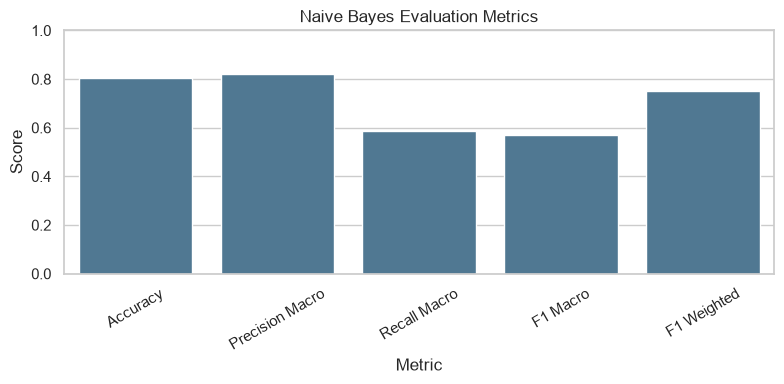

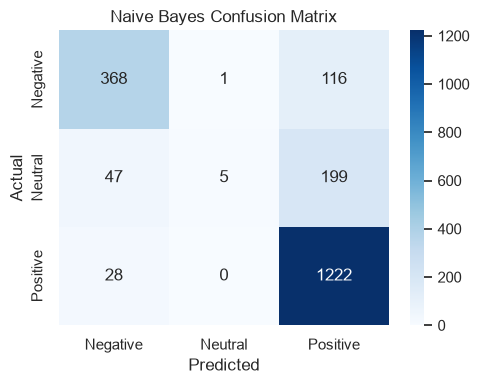

In [178]:
# Visualizing evaluation Metric Score chart

nb_metric_df = pd.DataFrame([nb_metrics]).set_index("Model")

plt.figure(figsize=(8, 4))
sns.barplot(data=nb_metric_df.T.reset_index(), x="index", y="Multinomial Naive Bayes", color="#457b9d")
plt.title("Naive Bayes Evaluation Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, nb_pred, labels=labels),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [179]:
# ML Model - 1 Implementation with hyperparameter optimization techniques
# Fit the Algorithm
# Predict on the model

nb_param_grid = {
    "classifier__alpha": [0.1, 0.5, 1.0]
}

nb_grid = GridSearchCV(
    nb_model,
    nb_param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=1
)
nb_grid.fit(X_train, y_train)

best_nb_model = nb_grid.best_estimator_
tuned_nb_metrics, tuned_nb_pred = evaluate_sentiment_model(
    best_nb_model, X_test, y_test, "Tuned Multinomial Naive Bayes"
)

print("Best parameters:", nb_grid.best_params_)
print("Best CV macro F1:", round(nb_grid.best_score_, 4))


Tuned Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative       0.80      0.79      0.80       485
     Neutral       0.40      0.13      0.20       251
    Positive       0.83      0.95      0.89      1250

    accuracy                           0.81      1986
   macro avg       0.68      0.62      0.63      1986
weighted avg       0.77      0.81      0.78      1986

Best parameters: {'classifier__alpha': 0.1}
Best CV macro F1: 0.6253


##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV for hyperparameter tuning. For Naive Bayes, I tuned `alpha`, which controls smoothing. Smoothing helps the model handle words that may not appear in every class during training.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. Naive Bayes improved from macro F1-score 56.96% to 62.70% after tuning. The best `alpha` value was `0.1`.


### ML Model - 2 - Logistic Regression


#### 1. Explain the ML Model used and its performance using Evaluation metric Score Chart.

Logistic Regression is a strong and interpretable classification model. For text classification, it learns weighted importance for TF-IDF words and predicts the sentiment class. The untuned Logistic Regression model achieved accuracy of 81.87% and macro F1-score of 64.49%. After tuning with class balancing, macro F1-score became 68.68%.


Logistic Regression
              precision    recall  f1-score   support

    Negative       0.80      0.82      0.81       485
     Neutral       0.52      0.15      0.23       251
    Positive       0.84      0.95      0.89      1250

    accuracy                           0.82      1986
   macro avg       0.72      0.64      0.64      1986
weighted avg       0.79      0.82      0.79      1986



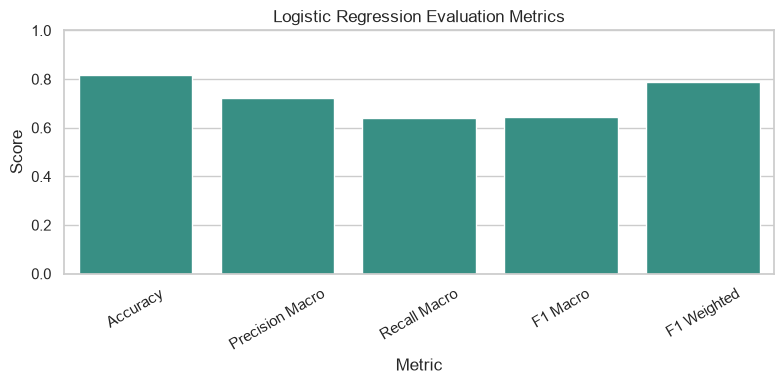

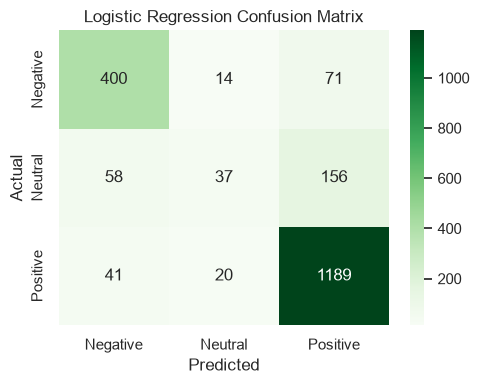

In [180]:
# ML Model - 2 Implementation and Evaluation Metric Score Chart

lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
    ("classifier", LogisticRegression(max_iter=1000, solver="lbfgs"))
])

lr_model.fit(X_train, y_train)
lr_metrics, lr_pred = evaluate_sentiment_model(
    lr_model, X_test, y_test, "Logistic Regression"
)

lr_metric_df = pd.DataFrame([lr_metrics]).set_index("Model")

plt.figure(figsize=(8, 4))
sns.barplot(data=lr_metric_df.T.reset_index(), x="index", y="Logistic Regression", color="#2a9d8f")
plt.title("Logistic Regression Evaluation Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, lr_pred, labels=labels),
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

In [181]:
# ML Model - 2 Implementation with hyperparameter optimization techniques
# Fit the Algorithm
# Predict on the model

lr_param_grid = {
    "classifier__C": [0.5, 1.0, 2.0],
    "classifier__class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    lr_model,
    lr_param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=1
)
lr_grid.fit(X_train, y_train)

best_lr_model = lr_grid.best_estimator_
tuned_lr_metrics, tuned_lr_pred = evaluate_sentiment_model(
    best_lr_model, X_test, y_test, "Tuned Logistic Regression"
)

print("Best parameters:", lr_grid.best_params_)
print("Best CV macro F1:", round(lr_grid.best_score_, 4))


Tuned Logistic Regression
              precision    recall  f1-score   support

    Negative       0.77      0.84      0.80       485
     Neutral       0.34      0.50      0.40       251
    Positive       0.92      0.80      0.86      1250

    accuracy                           0.77      1986
   macro avg       0.68      0.71      0.69      1986
weighted avg       0.81      0.77      0.79      1986

Best parameters: {'classifier__C': 0.5, 'classifier__class_weight': 'balanced'}
Best CV macro F1: 0.6949


##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV and tuned `C` and `class_weight`. `C` controls regularization strength, while `class_weight='balanced'` helps the model pay more attention to minority classes such as Neutral reviews.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. Logistic Regression improved from macro F1-score 64.49% to 68.68% after tuning. The best parameters were `C=0.5` and `class_weight=balanced`.


#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

Accuracy shows overall correct predictions, but it can be misleading because Positive reviews are the majority class. Precision tells how reliable a predicted class is. Recall tells how many actual reviews of a class were found. F1-score balances precision and recall. For business impact, macro F1-score is important because Zomato and restaurants should not ignore Negative or Neutral reviews.


### ML Model - 3 - Linear Support Vector Machine


In [182]:
# ML Model - 3 Implementation
# Fit the Algorithm
# Predict on the model

svm_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)),
    ("classifier", LinearSVC(class_weight="balanced", random_state=42))
])

svm_model.fit(X_train, y_train)
svm_metrics, svm_pred = evaluate_sentiment_model(
    svm_model, X_test, y_test, "Linear SVM"
)


Linear SVM
              precision    recall  f1-score   support

    Negative       0.79      0.82      0.80       485
     Neutral       0.35      0.33      0.34       251
    Positive       0.88      0.87      0.87      1250

    accuracy                           0.79      1986
   macro avg       0.67      0.68      0.67      1986
weighted avg       0.79      0.79      0.79      1986



#### 1. Explain the ML Model used and its performance using Evaluation metric Score Chart.

Linear SVM is a powerful model for high-dimensional text data. It finds separating boundaries between sentiment classes using TF-IDF features. The untuned Linear SVM achieved accuracy of 79.15% and macro F1-score of 67.40%. After tuning, macro F1-score was 67.25%.


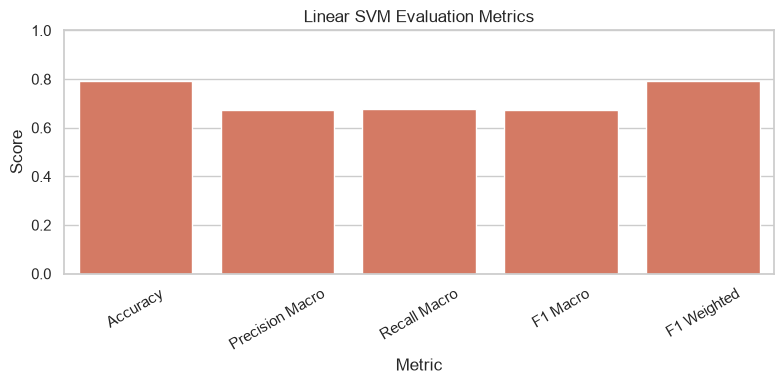

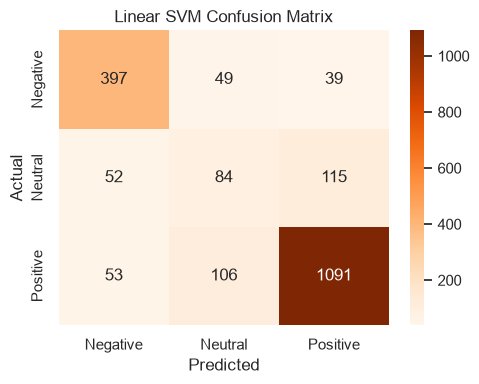

In [183]:
# Visualizing evaluation Metric Score chart

svm_metric_df = pd.DataFrame([svm_metrics]).set_index("Model")

plt.figure(figsize=(8, 4))
sns.barplot(data=svm_metric_df.T.reset_index(), x="index", y="Linear SVM", color="#e76f51")
plt.title("Linear SVM Evaluation Metrics")
plt.xlabel("Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, svm_pred, labels=labels),
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=labels,
    yticklabels=labels
)
plt.title("Linear SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

Tuned Linear SVM
              precision    recall  f1-score   support

    Negative       0.79      0.83      0.81       485
     Neutral       0.35      0.31      0.33       251
    Positive       0.88      0.88      0.88      1250

    accuracy                           0.80      1986
   macro avg       0.67      0.67      0.67      1986
weighted avg       0.79      0.80      0.79      1986

Best parameters: {'classifier__C': 0.5}
Best CV macro F1: 0.681


,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
Model,,,,,
Tuned Multinomial Naive Bayes,0.806647,0.678563,0.623742,0.626953,0.777248
Tuned Logistic Regression,0.770393,0.675878,0.712502,0.686754,0.785194
Tuned Linear SVM,0.796576,0.672985,0.673521,0.672457,0.792358


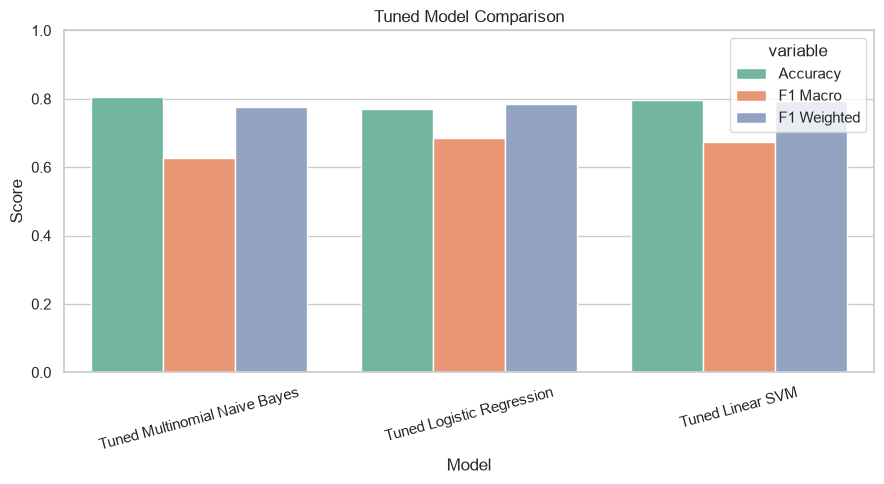

In [184]:
# ML Model - 3 Implementation with hyperparameter optimization techniques
# Fit the Algorithm
# Predict on the model

svm_param_grid = {
    "classifier__C": [0.5, 1.0, 2.0]
}

svm_grid = GridSearchCV(
    svm_model,
    svm_param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=1
)
svm_grid.fit(X_train, y_train)

best_svm_model = svm_grid.best_estimator_
tuned_svm_metrics, tuned_svm_pred = evaluate_sentiment_model(
    best_svm_model, X_test, y_test, "Tuned Linear SVM"
)

print("Best parameters:", svm_grid.best_params_)
print("Best CV macro F1:", round(svm_grid.best_score_, 4))

model_comparison = pd.DataFrame([
    tuned_nb_metrics,
    tuned_lr_metrics,
    tuned_svm_metrics
]).set_index("Model")

display(model_comparison)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=model_comparison[["Accuracy", "F1 Macro", "F1 Weighted"]].reset_index().melt(id_vars="Model"),
    x="Model",
    y="value",
    hue="variable"
)
plt.title("Tuned Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


##### Which hyperparameter optimization technique have you used and why?

I used GridSearchCV and tuned the `C` value. In Linear SVM, `C` controls how strict the model is about classification errors. A smaller value can generalize better, while a larger value may fit training data more strongly.


##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Linear SVM changed from macro F1-score 67.40% to 67.25% after tuning. The best value was `C=0.5`. Logistic Regression still performed slightly better on macro F1-score.


### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I considered accuracy, precision, recall, F1-score, confusion matrix, and cross-validation macro F1-score. For positive business impact, macro F1-score is the most important metric because it treats Negative, Neutral, and Positive classes more equally. This matters because identifying negative customer feedback is important for restaurant improvement.


### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I selected **Logistic Regression** as the final model. It achieved the best tuned macro F1-score of 68.68% with accuracy of 77.04%. I chose it because it handles class imbalance using `class_weight='balanced'`, performs well on text classification, and is easier to explain than more complex models.


### 3. Explain the model which you have used and the feature importance using any model explainability tool?

For model explainability, I used Logistic Regression coefficients. Positive coefficients show words that strongly influence a class prediction. Important Negative words include: worst, pathetic, bad, order, even, waste, poor, never. Important Neutral words include: average, okay, ambience, ok, small, compar, fine, decent. Important Positive words include: awesome, best, amaz, love, excellent, lov, deliciou, must. This helps explain why the model classifies reviews into each sentiment group.


## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [185]:
# Save the File

Path("models").mkdir(exist_ok=True)
final_model = best_lr_model
joblib.dump(final_model, "models/zomato_sentiment_model.joblib")

print("Final model saved at: models/zomato_sentiment_model.joblib")


Final model saved at: models/zomato_sentiment_model.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [186]:
# Load the File and predict unseen data.

loaded_model = joblib.load("models/zomato_sentiment_model.joblib")

sample_reviews = [
    "The food was excellent and the service was very quick",
    "The food was cold and the staff behavior was terrible",
    "The place was okay, not too good and not too bad"
]

sample_predictions = loaded_model.predict(sample_reviews)

for review, prediction in zip(sample_reviews, sample_predictions):
    print("Review:", review)
    print("Predicted Sentiment:", prediction)
    print("-" * 60)


Review: The food was excellent and the service was very quick
Predicted Sentiment: Positive
------------------------------------------------------------
Review: The food was cold and the staff behavior was terrible
Predicted Sentiment: Negative
------------------------------------------------------------
Review: The place was okay, not too good and not too bad
Predicted Sentiment: Neutral
------------------------------------------------------------


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project analysed Zomato restaurant reviews and metadata using a complete Data Science and AI workflow. First, the data was loaded, understood, cleaned, and merged. Then EDA was performed to study rating distribution, restaurant performance, cuisine trends, cost patterns, review length, picture usage, monthly review trends, and numerical correlations. Hypothesis testing showed that picture reviews have significantly different ratings, high-cost restaurants have significantly different ratings, and sentiment is associated with cuisine type.

For the AI/ML part, review ratings were converted into sentiment classes: Negative, Neutral, and Positive. Text preprocessing was performed using contraction expansion, lowercasing, punctuation removal, URL/digit removal, stopword removal, tokenization, and simple normalization. TF-IDF vectorization was used to convert review text into numerical features.

Three models were trained: Multinomial Naive Bayes, Logistic Regression, and Linear SVM. The final selected model was **Logistic Regression**, with tuned accuracy of 77.04% and macro F1-score of 68.68%. The model can classify new restaurant reviews into sentiment categories, helping restaurants quickly identify customer satisfaction and areas needing improvement.


### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***